# SPY Hourly Direction Model

Can a model trained on past hourly bars predict whether SPY's next hour is up, and does trading on that beat buy-and-hold? The data is 39,682 hourly SPY bars from Alpaca, 2016-06-28 through 2026-07-10, including extended hours.

- Sections 1–12 reproduce the original experiment: 14 engineered features, an exhaustive logistic-regression feature search and a final-test comparison.
- Sections 13–14 fix accounting and timing problems in that experiment one at a time, then re-select models using only past data.
- Sections 15–17 test planned improvements: normalized features, a more stable selection rule, extra feature families and policies that can hold cash.

The saved original run reports 33.74% net for the seven-feature logistic model, 22.80% for all features and 27.30% for buy-and-hold on the final 15%, after 1 bp per unit of turnover. An earlier 43.30% headline didn't match these outputs and was removed. From section 13 on, zero cost is the base case and 1 bp is a sensitivity check.

One caveat applies throughout: the final test period was already looked at during exploration, so every comparison here is retrospective rather than a fresh holdout.

## 1. Setup and how to run

Run from the repository root:

```sh
uv venv --python 3.12
uv pip install -r requirements.txt
uv run --no-sync jupyter notebook spy_hourly_model_full_experiment.ipynb
```

Sections 1–12 use Polars, pyarrow, NumPy, pandas, scikit-learn and matplotlib. Section 2 can download the data from Alpaca (this needs `alpaca-py` and API credentials), but the saved files below make that unnecessary:

- `data/raw/SPY/SPY-bars-1h-2016-06-28_2026-07-10.parquet`
- `data/processed/spy_hourly_feature_target_data_2016-06-28_2026-07-10.parquet`
- `data/processed/logistic_feature_search.sqlite` (opened read-only)

Sections 13–17 don't need Polars or Alpaca. Their helper functions are defined at the start of sections 13 and 15, and their unit tests run at the end of sections 14 and 17. Results are saved to the git-ignored `artifacts/spy_hourly_audit/` and `artifacts/spy_hourly_research/` together with a fingerprinted report. A saved report is reused only if the helper code, input files, settings and library versions all match; otherwise it's rebuilt. Measured results are also summarized in `PROJECT_PROGRESS.md`.

In [1]:
from datetime import date, datetime, time
from pathlib import Path
import hashlib
import itertools
import json
import os
import sqlite3
from zoneinfo import ZoneInfo

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
from IPython.display import display
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    log_loss,
    mean_squared_error,
    r2_score,
)
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

SYMBOL = 'SPY'
START_DATE = date(2016, 6, 28)
END_DATE = date(2026, 7, 10)
TRADING_HOURS_IN_DAY = 8
TRANSACTION_COST_BPS = 1.0
DOWNLOAD_IF_MISSING = True

STARTING_DIR = Path.cwd()
WORK_DIR = next(
    (candidate for candidate in [STARTING_DIR, *STARTING_DIR.parents]
     if (candidate / 'data' / 'raw' / SYMBOL).is_dir()),
    STARTING_DIR,
)
DATA_DIR = WORK_DIR / 'data'
RAW_DATA_PATH = DATA_DIR / 'raw' / SYMBOL
SNAPSHOT_PATH = RAW_DATA_PATH / f'{SYMBOL}-bars-1h-{START_DATE}_{END_DATE}.parquet'
PROCESSED_DATA_PATH = (
    DATA_DIR / 'processed'
    / f'spy_hourly_feature_target_data_{START_DATE}_{END_DATE}.parquet'
)
SEARCH_DB_PATH = DATA_DIR / 'processed' / 'logistic_feature_search.sqlite'

print(f'Working directory: {WORK_DIR}')
print(f'Pinned window: {START_DATE} through {END_DATE}')
print(f'Download missing data: {DOWNLOAD_IF_MISSING}')

Working directory: /u/eswarg06/ml-stock-project
Pinned window: 2016-06-28 through 2026-07-10
Download missing data: True


## 2. Download the pinned Alpaca data

A fresh run downloads the full window of hourly SIP bars from Alpaca and saves one parquet snapshot. The Alpaca import lives inside the download function, so working from the saved snapshot doesn't need `alpaca-py`.

In [2]:
def alpaca_credentials():
    api_key = os.getenv('APCA_API_KEY_ID')
    secret_key = os.getenv('APCA_API_SECRET_KEY')
    if not api_key or not secret_key:
        raise RuntimeError(
            'No compatible local data cache was found. Set APCA_API_KEY_ID and '
            'APCA_API_SECRET_KEY, then rerun this cell to download the pinned data.'
        )
    return api_key, secret_key

def download_pinned_snapshot(output_path):
    try:
        from alpaca.data.enums import DataFeed
        from alpaca.data.historical import StockHistoricalDataClient
        from alpaca.data.requests import StockBarsRequest
        from alpaca.data.timeframe import TimeFrame
    except ModuleNotFoundError as exc:
        raise RuntimeError(
            'alpaca-py is required for a fresh download. Run `%pip install alpaca-py` '
            'and restart the kernel.'
        ) from exc

    api_key, secret_key = alpaca_credentials()
    eastern = ZoneInfo('America/New_York')
    utc = ZoneInfo('UTC')
    request_start = datetime.combine(START_DATE, time(9, 30), eastern).astimezone(utc)
    request_end = datetime.combine(END_DATE, time(16, 0), eastern).astimezone(utc)
    request = StockBarsRequest(
        symbol_or_symbols=SYMBOL,
        start=request_start,
        end=request_end,
        timeframe=TimeFrame.Hour,
        feed=DataFeed.SIP,
    )
    print(f'Downloading {SYMBOL} hourly SIP bars from {START_DATE} through {END_DATE}...')
    downloaded = StockHistoricalDataClient(api_key, secret_key).get_stock_bars(request).df
    downloaded = downloaded.reset_index()
    downloaded = downloaded.rename(columns={
        'timestamp': 'datetime', 'vwap': 'mean_price', 'n': 'trade_count'
    })
    if 'symbol' in downloaded.columns:
        downloaded = downloaded.loc[downloaded['symbol'] == SYMBOL]
    if downloaded.empty:
        raise RuntimeError('Alpaca returned no bars for the pinned request.')

    bars = pl.from_pandas(downloaded).with_columns(
        pl.col('datetime').cast(pl.Datetime(time_zone='UTC')),
        pl.col('open').cast(pl.Float64),
        pl.col('high').cast(pl.Float64),
        pl.col('low').cast(pl.Float64),
        pl.col('close').cast(pl.Float64),
        pl.col('volume').cast(pl.Float64),
        pl.col('trade_count').cast(pl.Int64),
        pl.col('mean_price').cast(pl.Float64),
    ).with_columns(
        (pl.col('mean_price') * pl.col('volume')).alias('dollar_volume')
    ).select(
        'symbol', 'datetime', 'open', 'high', 'low', 'close', 'volume',
        'trade_count', 'mean_price', 'dollar_volume',
    ).sort('datetime')
    output_path.parent.mkdir(parents=True, exist_ok=True)
    bars.write_parquet(output_path)
    print(f'Wrote {bars.height:,} hourly bars to {output_path}')
    return output_path

if SNAPSHOT_PATH.exists():
    raw_bar_paths = [SNAPSHOT_PATH]
    print(f'Using pinned snapshot: {SNAPSHOT_PATH}')
elif DOWNLOAD_IF_MISSING:
    raw_bar_paths = [download_pinned_snapshot(SNAPSHOT_PATH)]
else:
    raise FileNotFoundError(
        f'No complete pinned cache found under {RAW_DATA_PATH}. '
        'Enable DOWNLOAD_IF_MISSING or provide the snapshot.'
    )

Using pinned snapshot: /u/eswarg06/ml-stock-project/data/raw/SPY/SPY-bars-1h-2016-06-28_2026-07-10.parquet


## 3. Read and validate hourly bars

Only bars inside the pinned window are kept, so adding newer files later can't shift the split boundaries. Then we check ordering, duplicate timestamps and missing closes.

In [3]:
intraday_bars = (
    pl.scan_parquet([str(path) for path in raw_bar_paths])
    .select(
        pl.col('symbol'),
        pl.col('datetime').cast(pl.Datetime(time_zone='UTC')),
        pl.col('open').cast(pl.Float64),
        pl.col('high').cast(pl.Float64),
        pl.col('low').cast(pl.Float64),
        pl.col('close').cast(pl.Float64),
        pl.col('volume').cast(pl.Float64),
        pl.col('trade_count').cast(pl.Int64),
        pl.col('mean_price').cast(pl.Float64),
        pl.col('dollar_volume').cast(pl.Float64),
    )
    .filter(pl.col('datetime').dt.date().is_between(START_DATE, END_DATE, closed='both'))
    .collect()
    .with_columns(
        pl.col('datetime').dt.date().alias('date'),
    )
    .select(
        'symbol', 'date', 'datetime', 'open', 'high', 'low', 'close',
        'volume', 'dollar_volume', 'trade_count', 'mean_price',
    )
    .sort('datetime')
)

raw_summary = intraday_bars.select(
    pl.len().alias('rows'),
    pl.col('datetime').min().alias('first_bar'),
    pl.col('datetime').max().alias('last_bar'),
    pl.col('date').n_unique().alias('trading_days'),
    pl.col('close').null_count().alias('null_closes'),
)
duplicate_timestamps = intraday_bars.height - intraday_bars.get_column('datetime').n_unique()
display(raw_summary)
print(f'Duplicate hourly timestamps: {duplicate_timestamps}')
display(intraday_bars.head(10))

rows,first_bar,last_bar,trading_days,null_closes
u32,"datetime[μs, UTC]","datetime[μs, UTC]",u32,u32
39682,2016-06-28 14:00:00 UTC,2026-07-10 20:00:00 UTC,2592,0


Duplicate hourly timestamps: 0


symbol,date,datetime,open,high,low,close,volume,dollar_volume,trade_count,mean_price
str,date,"datetime[μs, UTC]",f64,f64,f64,f64,f64,f64,i64,f64
"""SPY""",2016-06-28,2016-06-28 14:00:00 UTC,202.13,202.3,201.51,201.61,2.3102224e7,4.6636e9,99284,201.867639
"""SPY""",2016-06-28,2016-06-28 15:00:00 UTC,201.61,201.89,201.12,201.8135,1.7410279e7,3.5078e9,78489,201.479122
"""SPY""",2016-06-28,2016-06-28 16:00:00 UTC,201.82,202.11,201.54,201.9198,1.1985726e7,2.4188e9,46286,201.810195
"""SPY""",2016-06-28,2016-06-28 17:00:00 UTC,201.91,201.95,201.38,201.65,1.2254064e7,2.4713e9,46248,201.67192
"""SPY""",2016-06-28,2016-06-28 18:00:00 UTC,201.65,202.97,201.35,202.75,1.8995769e7,3.8392e9,72329,202.107164
"""SPY""",2016-06-28,2016-06-28 19:00:00 UTC,202.74,203.2,202.37,203.1725,3.5921169e7,7.2872e9,139071,202.867807
"""SPY""",2016-06-28,2016-06-28 20:00:00 UTC,203.17,203.47,203.11,203.32,1.4156163e7,2.8769e9,6276,203.226273
"""SPY""",2016-06-28,2016-06-28 21:00:00 UTC,203.3,204.3308,201.9191,203.3,1.115249e6,2.2651e8,238,203.100223
"""SPY""",2016-06-28,2016-06-28 22:00:00 UTC,203.3,203.32,203.06,203.27,84348.0,1.7137e7,258,203.168786


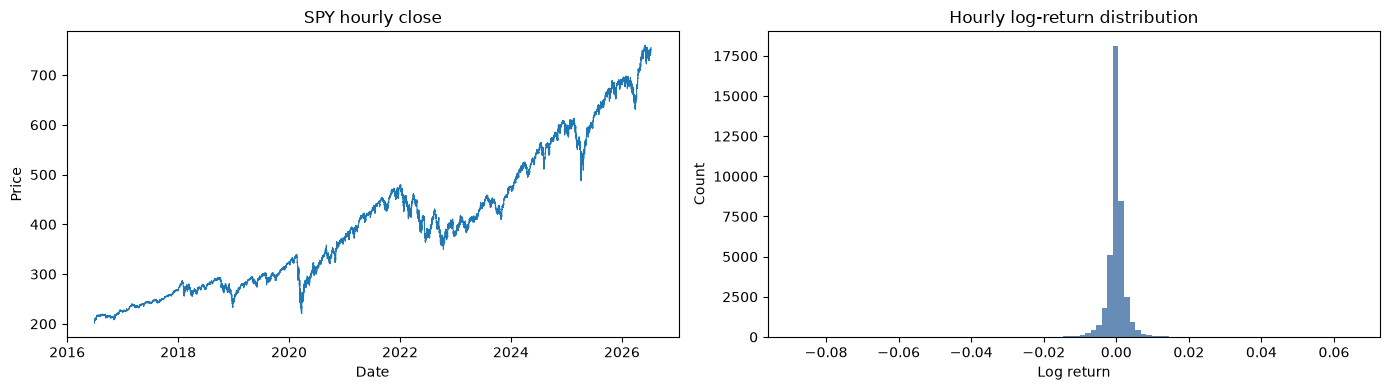

In [4]:
if not intraday_bars.get_column('datetime').is_sorted():
    raise ValueError('Hourly bars are not in chronological order.')
if duplicate_timestamps:
    raise ValueError(f'Found {duplicate_timestamps} duplicate hourly timestamps.')
if intraday_bars.get_column('close').null_count():
    raise ValueError('Close prices contain null values.')

hourly_returns_for_plot = intraday_bars.select(
    pl.col('datetime'),
    (pl.col('close') / pl.col('close').shift(1)).log().alias('log_return'),
).drop_nulls()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(intraday_bars['datetime'], intraday_bars['close'], linewidth=0.8)
axes[0].set(title='SPY hourly close', xlabel='Date', ylabel='Price')
axes[1].hist(hourly_returns_for_plot['log_return'], bins=100, color='#4c78a8', alpha=0.85)
axes[1].set(title='Hourly log-return distribution', xlabel='Log return', ylabel='Count')
plt.tight_layout()
plt.show()

## 4. Feature engineering

The target is bar `t`'s close-to-close log return. Every feature is built from prices shifted by at least one bar, so it only uses information through bar `t-1`. There are 14 candidates: distance from the 10-day moving average, two Bollinger-band positions, PGO, 1-day and 10-day average returns, and eight return lags. A "day" here is 8 bars, which section 13 revisits.

In [5]:
data = (
    intraday_bars.sort('datetime')
    .with_columns(
        pl.col('close').diff().alias('price_delta'),
        (pl.col('close') / pl.col('close').shift(1)).log().alias('log_return'),
        pl.col('close').shift(1).rolling_mean(TRADING_HOURS_IN_DAY * 10).alias('close_ma_10d'),
    )
    .with_columns(
        pl.col('price_delta').shift(1).alias('price_delta_lag_1'),
        (pl.col('close_ma_10d') - pl.col('close').shift(1)).alias('price_delta_w_ma_10d'),
    )
)

BOLLINGER_PERIOD = TRADING_HOURS_IN_DAY
BOLLINGER_STD_MULTIPLIER = 2
bollinger_close = pl.col('close').shift(1)
bollinger_mean = bollinger_close.rolling_mean(BOLLINGER_PERIOD)
bollinger_std = bollinger_close.rolling_std(BOLLINGER_PERIOD, ddof=0)
upper_band = bollinger_mean + BOLLINGER_STD_MULTIPLIER * bollinger_std
lower_band = bollinger_mean - BOLLINGER_STD_MULTIPLIER * bollinger_std

data = data.with_columns(
    ((bollinger_close - upper_band) / upper_band).alias('close_relative_to_upper_band'),
    ((bollinger_close - lower_band) / lower_band).alias('close_relative_to_lower_band'),
)

PGO_PERIOD = TRADING_HOURS_IN_DAY
pgo_close = pl.col('close').shift(1)
pgo_high = pl.col('high').shift(1)
pgo_low = pl.col('low').shift(1)
pgo_previous_close = pl.col('close').shift(2)
true_range = pl.max_horizontal(
    pgo_high - pgo_low,
    (pgo_high - pgo_previous_close).abs(),
    (pgo_low - pgo_previous_close).abs(),
)
pgo_close_mean = pgo_close.rolling_mean(PGO_PERIOD)
pgo_atr_mean = true_range.rolling_mean(PGO_PERIOD).rolling_mean(PGO_PERIOD)
data = data.with_columns(
    ((pgo_close - pgo_close_mean) / pgo_atr_mean).alias(f'PGO_{PGO_PERIOD}')
)

In [6]:
for lag in range(1, 9):
    data = data.with_columns(
        pl.col('log_return').shift(lag).alias(f'log_return_lag_{lag}')
    )

data = data.with_columns(
    pl.col('log_return_lag_1')
    .rolling_mean(TRADING_HOURS_IN_DAY)
    .alias('log_return_ma_1d_lag_1'),
    pl.col('log_return_lag_1')
    .rolling_mean(TRADING_HOURS_IN_DAY * 10)
    .alias('log_return_ma_10d_lag_1'),
)

features = [
    'price_delta_w_ma_10d',
    'close_relative_to_upper_band',
    'close_relative_to_lower_band',
    f'PGO_{PGO_PERIOD}',
    'log_return_ma_1d_lag_1',
    'log_return_ma_10d_lag_1',
] + [f'log_return_lag_{lag}' for lag in range(1, 9)]
target = 'log_return'

final_data_with_time = data.select('datetime', *features, target).drop_nulls()
final_data = final_data_with_time.select(*features, target)

feature_catalog = pd.DataFrame({
    'feature': features,
    'information_available': ['through t-1'] * len(features),
})
display(feature_catalog)
display(final_data_with_time.head())

,feature,information_available
0,price_delta_w_ma_10d,through t-1
1,close_relative_to_upper_band,through t-1
2,close_relative_to_lower_band,through t-1
3,PGO_8,through t-1
4,log_return_ma_1d_lag_1,through t-1
5,log_return_ma_10d_lag_1,through t-1
6,log_return_lag_1,through t-1
7,log_return_lag_2,through t-1
8,log_return_lag_3,through t-1
9,log_return_lag_4,through t-1


datetime,price_delta_w_ma_10d,close_relative_to_upper_band,close_relative_to_lower_band,PGO_8,log_return_ma_1d_lag_1,log_return_ma_10d_lag_1,log_return_lag_1,log_return_lag_2,log_return_lag_3,log_return_lag_4,log_return_lag_5,log_return_lag_6,log_return_lag_7,log_return_lag_8,log_return
"datetime[μs, UTC]",f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2016-07-06 17:00:00 UTC,-1.86303,0.000057,0.01241,1.928445,0.000923,0.000468,0.002775,0.002878,0.002117,0.000482,0.000626,0.000579,-0.002794,0.000722,-0.0011
2016-07-06 18:00:00 UTC,-1.542324,-0.002556,0.011433,1.324266,0.000695,0.000442,-0.0011,0.002775,0.002878,0.002117,0.000482,0.000626,0.000579,-0.002794,0.002436
2016-07-06 19:00:00 UTC,-1.956571,-0.002024,0.0131,1.601749,0.001349,0.000465,0.002436,-0.0011,0.002775,0.002878,0.002117,0.000482,0.000626,0.000579,0.000811
2016-07-06 20:00:00 UTC,-2.025321,-0.002645,0.012581,1.383672,0.001378,0.000492,0.000811,0.002436,-0.0011,0.002775,0.002878,0.002117,0.000482,0.000626,-0.000143
2016-07-06 21:00:00 UTC,-1.908196,-0.003353,0.010409,0.946633,0.001282,0.000422,-0.000143,0.000811,0.002436,-0.0011,0.002775,0.002878,0.002117,0.000482,0.0


## 5. Persist and verify the model-ready dataset

Saving the exact feature matrix means the modeling steps can be checked without redoing the download. The timestamp is kept in memory for reporting the splits but isn't a model input.

In [7]:
PROCESSED_DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
final_data.write_parquet(PROCESSED_DATA_PATH)
persisted_data = pl.read_parquet(PROCESSED_DATA_PATH)
if not persisted_data.equals(final_data):
    raise ValueError('Persisted feature data does not match the in-memory frame.')

dataset_summary = final_data_with_time.select(
    pl.len().alias('usable_rows'),
    pl.col('datetime').min().alias('first_usable_bar'),
    pl.col('datetime').max().alias('last_usable_bar'),
    pl.col(target).mean().alias('mean_log_return'),
    pl.col(target).std().alias('return_std'),
    (pl.col(target) > 0).mean().alias('positive_bar_rate'),
)
display(dataset_summary)
print(f'Features: {len(features)}')
print(f'Wrote verified dataset to: {PROCESSED_DATA_PATH}')

usable_rows,first_usable_bar,last_usable_bar,mean_log_return,return_std,positive_bar_rate
u32,"datetime[μs, UTC]","datetime[μs, UTC]",f64,f64,f64
39601,2016-07-06 17:00:00 UTC,2026-07-10 20:00:00 UTC,0.000032,0.002838,0.521502


Features: 14
Wrote verified dataset to: /u/eswarg06/ml-stock-project/data/processed/spy_hourly_feature_target_data_2016-06-28_2026-07-10.parquet


## 6. Original baseline experiments

This reproduces the original exploratory 80/20 chronological split with three baselines: linear regression on the return, logistic regression on direction and a small decision tree. Like the original table, it uses zero trading cost.

This 80/20 test overlaps the final 15% used later, so that final period isn't truly unseen, even though the feature search never trains on it.

In [8]:
X_baseline = final_data.select(features).to_numpy().astype(np.float64)
y_baseline = final_data.get_column(target).to_numpy().astype(np.float64)
baseline_split_idx = int(len(final_data) * 0.80)

X_train_raw, X_test_raw = X_baseline[:baseline_split_idx], X_baseline[baseline_split_idx:]
y_train, y_test = y_baseline[:baseline_split_idx], y_baseline[baseline_split_idx:]
baseline_scaler = StandardScaler()
X_train = baseline_scaler.fit_transform(X_train_raw)
X_test = baseline_scaler.transform(X_test_raw)

linear_baseline = LinearRegression().fit(X_train, y_train)
linear_test_pred = linear_baseline.predict(X_test)

y_train_direction = (y_train > 0).astype(np.int8)
y_test_direction = (y_test > 0).astype(np.int8)
logistic_baseline = LogisticRegression(max_iter=1_000, random_state=RANDOM_SEED)
logistic_baseline.fit(X_train, y_train_direction)
logistic_test_prob = logistic_baseline.predict_proba(X_test)[:, 1]
logistic_test_pred = (logistic_test_prob >= 0.5).astype(np.int8)

decision_tree_baseline = DecisionTreeRegressor(
    max_depth=5, min_samples_leaf=100, random_state=RANDOM_SEED
)
decision_tree_baseline.fit(X_train_raw, y_train)
decision_tree_test_pred = decision_tree_baseline.predict(X_test_raw)

print(f'Linear MSE: {mean_squared_error(y_test, linear_test_pred):.10f}')
print(f'Linear R²: {r2_score(y_test, linear_test_pred):.6f}')
print(f'Linear direction accuracy: {np.mean((linear_test_pred > 0) == (y_test > 0)):.2%}')
print()
print(f'Logistic log loss: {log_loss(y_test_direction, logistic_test_prob):.6f}')
print(f'Logistic direction accuracy: {accuracy_score(y_test_direction, logistic_test_pred):.2%}')
print(f'Logistic prediction counts: {dict(zip(*np.unique(logistic_test_pred, return_counts=True)))}')
print()
print(f'Decision-tree MSE: {mean_squared_error(y_test, decision_tree_test_pred):.10f}')
print(f'Decision-tree R²: {r2_score(y_test, decision_tree_test_pred):.6f}')
print(f'Decision-tree direction accuracy: {np.mean((decision_tree_test_pred > 0) == (y_test > 0)):.2%}')

Linear MSE: 0.0000070858
Linear R²: -0.008655
Linear direction accuracy: 49.84%

Logistic log loss: 0.692098
Logistic direction accuracy: 52.25%
Logistic prediction counts: {np.int8(0): np.int64(136), np.int8(1): np.int64(7785)}

Decision-tree MSE: 0.0000071515
Decision-tree R²: -0.018016
Decision-tree direction accuracy: 52.38%


In [9]:
BARS_PER_YEAR = 252 * TRADING_HOURS_IN_DAY

def baseline_strategy_statistics(name, position):
    returns = position * y_test
    equity = np.exp(np.cumsum(returns))
    drawdown = equity / np.maximum.accumulate(equity) - 1.0
    return_std = returns.std(ddof=1)
    return {
        'model': name,
        'direction_accuracy': np.mean((position > 0) == (y_test > 0)),
        'net_return': equity[-1] - 1.0,
        'annualized_sharpe': (returns.mean() / return_std * np.sqrt(BARS_PER_YEAR)),
        'max_drawdown': drawdown.min(),
        'hit_rate': np.mean(returns > 0),
        'long_rate': np.mean(position > 0),
        'position_changes': np.count_nonzero(np.diff(position)),
    }

baseline_positions = {
    'Buy and hold': np.ones_like(y_test),
    'Linear regression': np.where(linear_test_pred > 0, 1.0, -1.0),
    'Logistic regression': np.where(logistic_test_pred == 1, 1.0, -1.0),
    'Decision tree': np.where(decision_tree_test_pred > 0, 1.0, -1.0),
}
baseline_stats = pd.DataFrame([
    baseline_strategy_statistics(name, position)
    for name, position in baseline_positions.items()
])
display(baseline_stats)

coefficient_table = pd.DataFrame({
    'feature': features,
    'linear_coefficient': linear_baseline.coef_,
    'logistic_coefficient': logistic_baseline.coef_[0],
}).sort_values('logistic_coefficient', key=np.abs, ascending=False)
display(coefficient_table)

,model,direction_accuracy,net_return,annualized_sharpe,max_drawdown,hit_rate,long_rate,position_changes
0,Buy and hold,0.523798,0.364490,0.664615,-0.204531,0.523798,1.000000,0
1,Linear regression,0.498422,0.130129,0.261586,-0.169654,0.496654,0.578967,3788
2,Logistic regression,0.522535,0.450288,0.795063,-0.178436,0.522535,0.982830,184
3,Decision tree,0.523798,0.172980,0.341171,-0.286266,0.523798,0.997223,36


,feature,linear_coefficient,logistic_coefficient
0,price_delta_w_ma_10d,0.000012,0.016181
9,log_return_lag_4,0.000475,0.014638
3,PGO_8,0.000197,-0.013075
11,log_return_lag_6,-0.000007,-0.012166
13,log_return_lag_8,-0.000316,0.012018
2,close_relative_to_lower_band,-0.001788,-0.011206
1,close_relative_to_upper_band,-0.001979,0.005879
4,log_return_ma_1d_lag_1,0.000967,0.004198
7,log_return_lag_2,0.000896,-0.003845
5,log_return_ma_10d_lag_1,0.000020,0.003250


## 7. Exhaustive logistic-regression feature search

The first 70% of bars train each candidate, the next 15% rank the feature subsets, and the final 15% is held out of the search (although, as noted above, the baselines already saw it). All 16,383 nonempty subsets of the 14 features are tested and ranked by validation net return after 1 bp per unit of turnover.

Results are checkpointed in SQLite under a hash of the data and configuration, so results from a different setup can't get mixed in.

In [10]:
X_feature_search = final_data.select(features).to_numpy().astype(np.float64)
y_feature_search = final_data.get_column(target).to_numpy().astype(np.float64)
feature_search_train_end = int(len(y_feature_search) * 0.70)
feature_search_validation_end = int(len(y_feature_search) * 0.85)

X_feature_train = X_feature_search[:feature_search_train_end]
y_feature_train = y_feature_search[:feature_search_train_end]
X_feature_validation = X_feature_search[feature_search_train_end:feature_search_validation_end]
y_feature_validation = y_feature_search[feature_search_train_end:feature_search_validation_end]
X_feature_test = X_feature_search[feature_search_validation_end:]
y_feature_test = y_feature_search[feature_search_validation_end:]

split_summary = pd.DataFrame([
    {
        'split': 'train', 'rows': feature_search_train_end,
        'start': final_data_with_time[0, 'datetime'],
        'end': final_data_with_time[feature_search_train_end - 1, 'datetime'],
    },
    {
        'split': 'validation',
        'rows': feature_search_validation_end - feature_search_train_end,
        'start': final_data_with_time[feature_search_train_end, 'datetime'],
        'end': final_data_with_time[feature_search_validation_end - 1, 'datetime'],
    },
    {
        'split': 'final test', 'rows': len(y_feature_test),
        'start': final_data_with_time[feature_search_validation_end, 'datetime'],
        'end': final_data_with_time[-1, 'datetime'],
    },
])
display(split_summary)

,split,rows,start,end
0,train,27720,2016-07-06 17:00:00+00:00,2023-07-24 23:00:00+00:00
1,validation,5940,2023-07-25 08:00:00+00:00,2025-01-15 19:00:00+00:00
2,final test,5941,2025-01-15 20:00:00+00:00,2026-07-10 20:00:00+00:00


In [11]:
feature_search_cost = TRANSACTION_COST_BPS / 10_000.0

def strategy_metrics(predictions, realized_log_returns):
    positions = np.where(np.asarray(predictions) == 1, 1.0, -1.0)
    turnover_by_bar = np.abs(np.diff(positions, prepend=0.0))
    gross_log_returns = positions * np.asarray(realized_log_returns)
    net_log_returns = gross_log_returns - turnover_by_bar * feature_search_cost
    return {
        'net_return': float(np.exp(net_log_returns.sum()) - 1.0),
        'gross_return': float(np.exp(gross_log_returns.sum()) - 1.0),
        'position_changes': int(np.count_nonzero(np.diff(positions))),
        'turnover': float(turnover_by_bar.sum()),
        'long_rate': float(np.mean(positions > 0)),
    }

data_hasher = hashlib.sha256()
data_hasher.update(X_feature_search.tobytes())
data_hasher.update(y_feature_search.tobytes())
search_config = json.dumps({
    'features': features,
    'cost_bps': TRANSACTION_COST_BPS,
    'train_end': feature_search_train_end,
    'validation_end': feature_search_validation_end,
    'data_hash': data_hasher.hexdigest(),
}, sort_keys=True)
search_id = hashlib.sha256(search_config.encode()).hexdigest()

SEARCH_DB_PATH.parent.mkdir(parents=True, exist_ok=True)
with sqlite3.connect(SEARCH_DB_PATH) as search_db:
    search_db.execute('''
        CREATE TABLE IF NOT EXISTS feature_search_results (
            search_id TEXT NOT NULL,
            feature_key TEXT NOT NULL,
            features_json TEXT NOT NULL,
            feature_count INTEGER NOT NULL,
            net_return REAL NOT NULL,
            gross_return REAL NOT NULL,
            position_changes INTEGER NOT NULL,
            turnover REAL NOT NULL,
            long_rate REAL NOT NULL,
            PRIMARY KEY (search_id, feature_key)
        )
    ''')
    completed_feature_keys = {
        row[0] for row in search_db.execute(
            'SELECT feature_key FROM feature_search_results WHERE search_id = ?',
            (search_id,),
        )
    }
    total_feature_subsets = 2 ** len(features) - 1
    print(f'Resuming with {len(completed_feature_keys):,}/{total_feature_subsets:,} combinations complete.')

    for subset_size in range(1, len(features) + 1):
        print(f'Testing feature subsets of size {subset_size}...')
        for feature_subset in itertools.combinations(features, subset_size):
            feature_key = json.dumps(list(feature_subset), separators=(',', ':'))
            if feature_key in completed_feature_keys:
                continue
            indices = [features.index(name) for name in feature_subset]
            scaler = StandardScaler()
            X_train_subset = scaler.fit_transform(X_feature_train[:, indices])
            X_validation_subset = scaler.transform(X_feature_validation[:, indices])
            model = LogisticRegression(max_iter=1_000, random_state=RANDOM_SEED)
            model.fit(X_train_subset, (y_feature_train > 0).astype(np.int8))
            validation_predictions = model.predict(X_validation_subset)
            metrics = strategy_metrics(validation_predictions, y_feature_validation)
            search_db.execute(
                'INSERT OR REPLACE INTO feature_search_results VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?)',
                (
                    search_id, feature_key, json.dumps(list(feature_subset)), len(feature_subset),
                    metrics['net_return'], metrics['gross_return'],
                    metrics['position_changes'], metrics['turnover'], metrics['long_rate'],
                ),
            )
            search_db.commit()
            completed_feature_keys.add(feature_key)

    feature_search_results_df = pd.read_sql_query(
        'SELECT * FROM feature_search_results WHERE search_id = ?',
        search_db, params=(search_id,),
    )

feature_search_results_df = (
    feature_search_results_df
    .assign(features=lambda frame: frame['features_json'].map(lambda value: tuple(json.loads(value))))
    .sort_values('net_return', ascending=False)
    .reset_index(drop=True)
)
print(f'Search complete. Checkpoint: {SEARCH_DB_PATH}')
display(feature_search_results_df.head(20))

Resuming with 16,383/16,383 combinations complete.
Testing feature subsets of size 1...
Testing feature subsets of size 2...
Testing feature subsets of size 3...
Testing feature subsets of size 4...
Testing feature subsets of size 5...


Testing feature subsets of size 6...
Testing feature subsets of size 7...
Testing feature subsets of size 8...
Testing feature subsets of size 9...
Testing feature subsets of size 10...
Testing feature subsets of size 11...
Testing feature subsets of size 12...
Testing feature subsets of size 13...
Testing feature subsets of size 14...
Search complete. Checkpoint: /u/eswarg06/ml-stock-project/data/processed/logistic_feature_search.sqlite


,search_id,feature_key,features_json,feature_count,net_return,gross_return,position_changes,turnover,long_rate,features
0,f79a1d781c8e7762c9d487145d89e0d574c3944188b21f...,"[""close_relative_to_upper_band"",""close_relativ...","[""close_relative_to_upper_band"", ""close_relati...",7,0.409810,0.420708,38,77.0,0.995791,"(close_relative_to_upper_band, close_relative_..."
1,f79a1d781c8e7762c9d487145d89e0d574c3944188b21f...,"[""close_relative_to_upper_band"",""PGO_8"",""log_r...","[""close_relative_to_upper_band"", ""PGO_8"", ""log...",7,0.406456,0.418461,42,85.0,0.995118,"(close_relative_to_upper_band, PGO_8, log_retu..."
2,f79a1d781c8e7762c9d487145d89e0d574c3944188b21f...,"[""close_relative_to_upper_band"",""PGO_8"",""log_r...","[""close_relative_to_upper_band"", ""PGO_8"", ""log...",7,0.403430,0.414844,40,81.0,0.995455,"(close_relative_to_upper_band, PGO_8, log_retu..."
3,f79a1d781c8e7762c9d487145d89e0d574c3944188b21f...,"[""close_relative_to_upper_band"",""close_relativ...","[""close_relative_to_upper_band"", ""close_relati...",7,0.402514,0.413920,40,81.0,0.995286,"(close_relative_to_upper_band, close_relative_..."
4,f79a1d781c8e7762c9d487145d89e0d574c3944188b21f...,"[""close_relative_to_upper_band"",""PGO_8"",""log_r...","[""close_relative_to_upper_band"", ""PGO_8"", ""log...",8,0.402198,0.415300,46,93.0,0.994949,"(close_relative_to_upper_band, PGO_8, log_retu..."
5,f79a1d781c8e7762c9d487145d89e0d574c3944188b21f...,"[""close_relative_to_upper_band"",""PGO_8"",""log_r...","[""close_relative_to_upper_band"", ""PGO_8"", ""log...",7,0.402198,0.415300,46,93.0,0.994949,"(close_relative_to_upper_band, PGO_8, log_retu..."
6,f79a1d781c8e7762c9d487145d89e0d574c3944188b21f...,"[""close_relative_to_upper_band"",""PGO_8"",""log_r...","[""close_relative_to_upper_band"", ""PGO_8"", ""log...",6,0.402127,0.414096,42,85.0,0.995286,"(close_relative_to_upper_band, PGO_8, log_retu..."
7,f79a1d781c8e7762c9d487145d89e0d574c3944188b21f...,"[""close_relative_to_upper_band"",""close_relativ...","[""close_relative_to_upper_band"", ""close_relati...",9,0.401779,0.412614,38,77.0,0.995791,"(close_relative_to_upper_band, close_relative_..."
8,f79a1d781c8e7762c9d487145d89e0d574c3944188b21f...,"[""close_relative_to_upper_band"",""close_relativ...","[""close_relative_to_upper_band"", ""close_relati...",8,0.400766,0.411029,36,73.0,0.996128,"(close_relative_to_upper_band, close_relative_..."
9,f79a1d781c8e7762c9d487145d89e0d574c3944188b21f...,"[""close_relative_to_upper_band"",""close_relativ...","[""close_relative_to_upper_band"", ""close_relati...",8,0.399972,0.412488,44,89.0,0.995118,"(close_relative_to_upper_band, close_relative_..."


## 8. Refit and evaluate the validation-selected model

The best subset on validation is refit on the first 85% and evaluated on the final 15%.

In [12]:
best_features = list(feature_search_results_df.iloc[0]['features'])
best_feature_indices = [features.index(name) for name in best_features]
X_development_selected = X_feature_search[:feature_search_validation_end, best_feature_indices]
y_development = y_feature_search[:feature_search_validation_end]
X_final_test_selected = X_feature_test[:, best_feature_indices]

selected_scaler = StandardScaler()
X_development_selected_scaled = selected_scaler.fit_transform(X_development_selected)
X_final_test_selected_scaled = selected_scaler.transform(X_final_test_selected)
selected_model = LogisticRegression(max_iter=1_000, random_state=RANDOM_SEED)
selected_model.fit(
    X_development_selected_scaled,
    (y_development > 0).astype(np.int8),
)
selected_test_probabilities = selected_model.predict_proba(X_final_test_selected_scaled)[:, 1]
selected_test_predictions = (selected_test_probabilities >= 0.5).astype(np.int8)
selected_test_metrics = strategy_metrics(selected_test_predictions, y_feature_test)

print('Best validation feature combination:')
for feature in best_features:
    print(f'  {feature}')
print(f"Validation net return: {feature_search_results_df.iloc[0]['net_return']:.2%}")
print(f"Final-test net return: {selected_test_metrics['net_return']:.2%}")
print(f"Final-test gross return: {selected_test_metrics['gross_return']:.2%}")
print(f"Direction accuracy: {accuracy_score(y_feature_test > 0, selected_test_predictions):.2%}")
print(f"Position changes: {selected_test_metrics['position_changes']}")
print(f"Long rate: {selected_test_metrics['long_rate']:.2%}")

Best validation feature combination:
  close_relative_to_upper_band
  close_relative_to_lower_band
  PGO_8
  log_return_ma_1d_lag_1
  log_return_lag_3
  log_return_lag_4
  log_return_lag_8
Validation net return: 40.98%
Final-test net return: 33.74%
Final-test gross return: 36.18%
Direction accuracy: 52.35%
Position changes: 90
Long rate: 99.04%


## 9. Historical all-feature logistic comparison

Same setup as the selected model (training rows, scaling, 0.5 threshold, test window and cost function), but with all 14 features. It returns 22.80% net.

In [13]:
all_feature_scaler = StandardScaler()
X_development_all = all_feature_scaler.fit_transform(
    X_feature_search[:feature_search_validation_end]
)
X_final_test_all = all_feature_scaler.transform(X_feature_test)
all_feature_model = LogisticRegression(max_iter=1_000, random_state=RANDOM_SEED)
all_feature_model.fit(
    X_development_all,
    (y_feature_search[:feature_search_validation_end] > 0).astype(np.int8),
)
all_feature_test_probabilities = all_feature_model.predict_proba(X_final_test_all)[:, 1]
all_feature_test_predictions = (all_feature_test_probabilities >= 0.5).astype(np.int8)
all_feature_test_metrics = strategy_metrics(all_feature_test_predictions, y_feature_test)

print(f"All-feature final-test net return: {all_feature_test_metrics['net_return']:.2%}")
print(f"All-feature final-test gross return: {all_feature_test_metrics['gross_return']:.2%}")
print(f"Direction accuracy: {accuracy_score(y_feature_test > 0, all_feature_test_predictions):.2%}")
print(f"Log loss: {log_loss(y_feature_test > 0, all_feature_test_probabilities):.6f}")
print(f"Position changes: {all_feature_test_metrics['position_changes']}")
print(f"Long rate: {all_feature_test_metrics['long_rate']:.2%}")

all_feature_coefficients = pd.DataFrame({
    'feature': features,
    'standardized_coefficient': all_feature_model.coef_[0],
}).sort_values('standardized_coefficient', key=np.abs, ascending=False)
display(all_feature_coefficients)

All-feature final-test net return: 22.80%
All-feature final-test gross return: 25.74%
Direction accuracy: 52.25%
Log loss: 0.692075
Position changes: 118
Long rate: 98.80%


,feature,standardized_coefficient
9,log_return_lag_4,0.014819
3,PGO_8,-0.013385
13,log_return_lag_8,0.013337
11,log_return_lag_6,-0.011718
2,close_relative_to_lower_band,-0.010167
0,price_delta_w_ma_10d,0.006463
1,close_relative_to_upper_band,0.005366
5,log_return_ma_10d_lag_1,-0.003718
4,log_return_ma_1d_lag_1,0.003485
7,log_return_lag_2,-0.002778


## 10. Fair final-test comparison

All strategies use the same final 15%, compound the same hourly log returns and pay 1 bp per unit of position change, so a long-to-short flip costs 2 bp.

In [14]:
buy_hold_predictions = np.ones(len(y_feature_test), dtype=np.int8)
buy_hold_metrics = strategy_metrics(buy_hold_predictions, y_feature_test)
fair_final_test_comparison = pd.DataFrame([
    {
        'model': 'Logistic regression (all features)',
        'feature_count': len(features),
        'direction_accuracy': accuracy_score(y_feature_test > 0, all_feature_test_predictions),
        **all_feature_test_metrics,
    },
    {
        'model': 'Logistic regression (selected features)',
        'feature_count': len(best_features),
        'direction_accuracy': accuracy_score(y_feature_test > 0, selected_test_predictions),
        **selected_test_metrics,
    },
    {
        'model': 'Buy and hold',
        'feature_count': 0,
        'direction_accuracy': accuracy_score(y_feature_test > 0, buy_hold_predictions),
        **buy_hold_metrics,
    },
]).sort_values('net_return', ascending=False).reset_index(drop=True)

display(fair_final_test_comparison.style.format({
    'direction_accuracy': '{:.2%}',
    'net_return': '{:.2%}',
    'gross_return': '{:.2%}',
    'long_rate': '{:.2%}',
    'turnover': '{:.1f}',
}))

,model,feature_count,direction_accuracy,net_return,gross_return,position_changes,turnover,long_rate
0,Logistic regression (selected features),7,52.35%,33.74%,36.18%,90,181.0,99.04%
1,Buy and hold,0,52.30%,27.30%,27.31%,0,1.0,100.00%
2,Logistic regression (all features),14,52.25%,22.80%,25.74%,118,237.0,98.80%


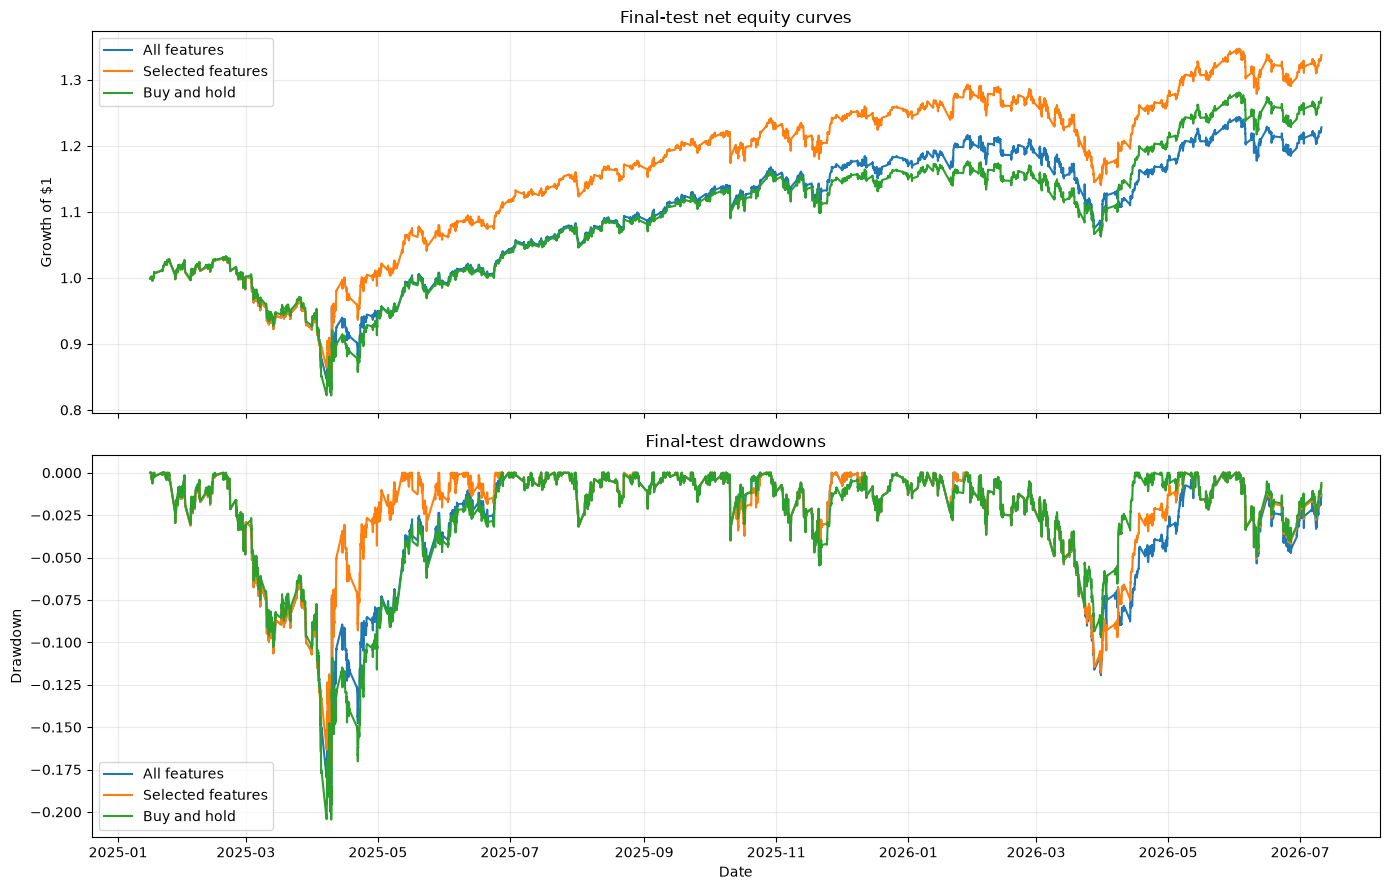

,model,annualized_sharpe,max_drawdown,hit_rate,short_bar_return_contribution
0,All features,0.557873,-0.183389,0.521966,-0.017996
1,Selected features,0.789940,-0.172761,0.523144,0.024679
2,Buy and hold,0.655577,-0.204531,0.522976,0.000000


In [15]:
def strategy_path(predictions, realized_log_returns):
    positions = np.where(np.asarray(predictions) == 1, 1.0, -1.0)
    turnover = np.abs(np.diff(positions, prepend=0.0))
    net_log_returns = positions * np.asarray(realized_log_returns) - turnover * feature_search_cost
    equity = np.exp(np.cumsum(net_log_returns))
    drawdown = equity / np.maximum.accumulate(equity) - 1.0
    return equity, drawdown, net_log_returns, positions

strategy_predictions = {
    'All features': all_feature_test_predictions,
    'Selected features': selected_test_predictions,
    'Buy and hold': buy_hold_predictions,
}
strategy_paths = {
    name: strategy_path(predictions, y_feature_test)
    for name, predictions in strategy_predictions.items()
}
test_datetimes = final_data_with_time['datetime'].to_numpy()[feature_search_validation_end:]

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
for name, (equity, drawdown, _, _) in strategy_paths.items():
    axes[0].plot(test_datetimes, equity, label=name)
    axes[1].plot(test_datetimes, drawdown, label=name)
axes[0].set(title='Final-test net equity curves', ylabel='Growth of $1')
axes[1].set(title='Final-test drawdowns', ylabel='Drawdown', xlabel='Date')
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend()
plt.tight_layout()
plt.show()

risk_rows = []
for name, (_, drawdown, net_returns, positions) in strategy_paths.items():
    return_std = net_returns.std(ddof=1)
    risk_rows.append({
        'model': name,
        'annualized_sharpe': net_returns.mean() / return_std * np.sqrt(BARS_PER_YEAR),
        'max_drawdown': drawdown.min(),
        'hit_rate': np.mean(net_returns > 0),
        'short_bar_return_contribution': net_returns[positions < 0].sum(),
    })
display(pd.DataFrame(risk_rows))

## 11. Classification diagnostics

Accuracy alone doesn't show how the strategy behaves. The confusion matrices, probability histogram and exposure plot show how rarely the models leave a long position.

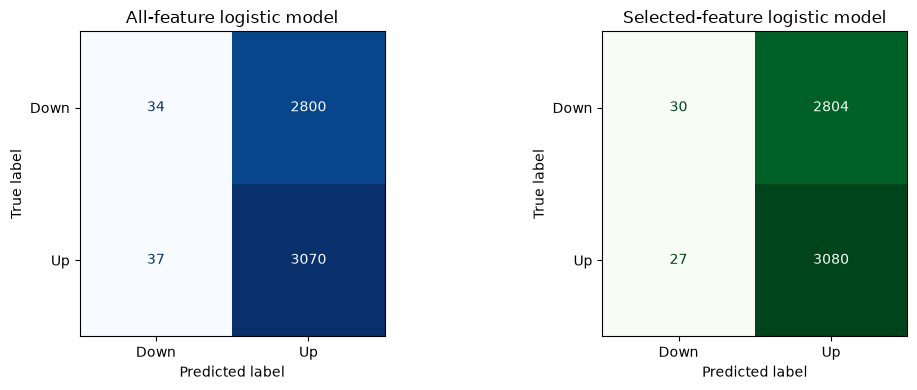

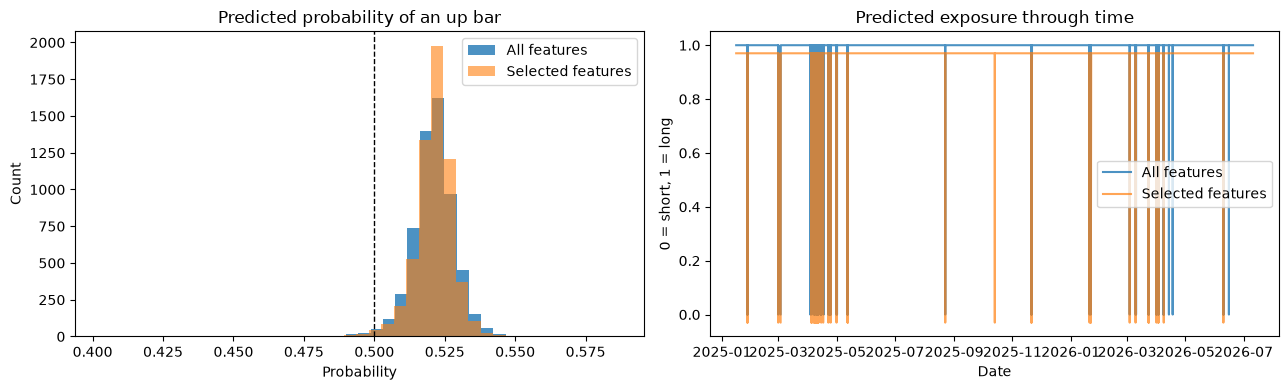

In [16]:
actual_direction = (y_feature_test > 0).astype(np.int8)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(
    actual_direction, all_feature_test_predictions,
    display_labels=['Down', 'Up'], cmap='Blues', ax=axes[0], colorbar=False,
)
axes[0].set_title('All-feature logistic model')
ConfusionMatrixDisplay.from_predictions(
    actual_direction, selected_test_predictions,
    display_labels=['Down', 'Up'], cmap='Greens', ax=axes[1], colorbar=False,
)
axes[1].set_title('Selected-feature logistic model')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(all_feature_test_probabilities, bins=40, alpha=0.8, label='All features')
axes[0].hist(selected_test_probabilities, bins=40, alpha=0.6, label='Selected features')
axes[0].axvline(0.5, color='black', linestyle='--', linewidth=1)
axes[0].set(title='Predicted probability of an up bar', xlabel='Probability', ylabel='Count')
axes[0].legend()
axes[1].plot(test_datetimes, all_feature_test_predictions, label='All features', alpha=0.8)
axes[1].plot(test_datetimes, selected_test_predictions - 0.03, label='Selected features', alpha=0.7)
axes[1].set(title='Predicted exposure through time', xlabel='Date', ylabel='0 = short, 1 = long')
axes[1].legend()
plt.tight_layout()
plt.show()

## 12. What the original experiment actually shows

The seven-feature logistic model returned 33.74% net, against 27.30% for buy-and-hold and 22.80% for the all-feature model (1 bp turnover cost). Its validation return was 40.98%. These numbers come straight from the processed matrix and the matching SQLite search; the older 43.30%/31.17%/26.60% text was stale.

The models are long on about 99% of test bars, so most of their return is market exposure, and the small accuracy edge over always-long isn't evidence of forecasting skill. Searching 16,383 subsets also adds selection risk, since a good validation score can be luck.

The original backtest has mechanical problems too: it uses negative log returns for shorts, enters at the prior close and treats 8 bars as a day, while the extended-hours data actually has a median of 16 bars per New York session. Section 13 keeps the original result as a reference and fixes these one at a time.

## 13. Controlled repair audit on the original test timestamps

This section doesn't need the Polars cells above; the four code cells below define its helpers. It starts from the saved Parquet files and the read-only SQLite winner, reproduces the original feature matrix and predictions exactly, then applies one fix at a time. The 16,383-subset search isn't rerun.

Every variant is scored on the same 5,941 hourly test timestamps (2025-01-15 to 2026-07-10). The original seven-feature model stays frozen, so each row isolates one change; it doesn't make that model an independently validated winner.

- A: the original sign-times-log-return accounting, as a reproduction check.
- B: a cash-and-shares ledger with exact costs on traded dollars and a final liquidation. Shares stay fixed until the position flips, so shorts no longer earn reciprocal-price returns or get rebalanced for free every hour.
- C: the same forecasts, but trades fill at the next observed open. An existing position earns the gap before a change; a new position doesn't get the pre-entry gap. Observed opens are still idealized fills.
- C2: refit with the old windows, but only on labels known before the cutoff. This isolates the purge from the feature changes.
- D: replace the 8- and 80-bar "day" windows with real New York sessions. Each window ends at a completed bar and starts at the same clock time one or ten sessions earlier, so weekends, DST and missing hours are handled correctly. The original double-SMA PGO smoothing is kept so only the window changes.
- E: refit on open-to-close direction labels, which leave out the gap that already happened before entry.
- E2: refit on open-to-next-open labels, matching the time between trading opportunities. A label becomes usable only at that next open (the last bar has none, but it can still be marked and liquidated).
- F: add one extra bar of signal delay to the intrabar model, as a latency check rather than a candidate model.

Zero cost is the base case; 1 bp is a sensitivity, not a measured commission. Sharpe comes from New York daily portfolio returns times sqrt(252) instead of assuming eight independent bars per day. Dividends, borrow fees, margin and quote spreads aren't modeled.

In [17]:
# Section 13-14 helpers: settings, fingerprint and feature windows
from dataclasses import asdict, dataclass, replace
import hashlib
import inspect
import json
from pathlib import Path
import sqlite3
from typing import Literal

import numpy as np
import pandas as pd
from pandas.api.indexers import BaseIndexer
import sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits


def code_hash(*functions):
    """Hash of the functions' source: saved results are rebuilt when the code changes."""
    return hashlib.sha256("".join(inspect.getsource(f) for f in functions).encode()).hexdigest()


RAW_NAME = "SPY-bars-1h-2016-06-28_2026-07-10.parquet"


PROCESSED_NAME = "spy_hourly_feature_target_data_2016-06-28_2026-07-10.parquet"


LEGACY_COLUMNS = [
    "price_delta_w_ma_10d",
    "close_relative_to_upper_band",
    "close_relative_to_lower_band",
    "PGO_8",
    "log_return_ma_1d_lag_1",
    "log_return_ma_10d_lag_1",
    *[f"log_return_lag_{lag}" for lag in range(1, 9)],
]


FEATURES = [
    "ma_distance",
    "upper_relative",
    "lower_relative",
    "pgo",
    "mean_return_1_session",
    "mean_return_10_sessions",
    *[f"return_lag_{lag}" for lag in range(1, 9)],
]


FEATURE_NAMES = dict(zip(LEGACY_COLUMNS, FEATURES))


@dataclass(frozen=True)
class AuditConfig:
    cost_bps: float = 0.0
    sensitivity_cost_bps: float = 1.0
    outer_start: str = "2020-01-01"
    inner_sessions: int = 126
    regularization: tuple[float, ...] = (0.1, 1.0, 10.0)
    threads: int = 4
    walk_target: Literal["return_oc", "return_oo"] = "return_oc"


def audit_fingerprint(data_dir="data", config=AuditConfig()):
    root = Path(data_dir)
    files = [
        root / "raw" / "SPY" / RAW_NAME,
        root / "processed" / PROCESSED_NAME,
        root / "processed" / "logistic_feature_search.sqlite",
    ]
    return {
        "implementation_sha256": code_hash(
            _session_window, make_features, cash_share_path, _path_summary, _fit, _predict,
            _load_cached, _training_rows, _label_deadline, _choose_on_past, _walk_forward, run_audit,
        ),
        "inputs": {
            str(path.relative_to(root)): hashlib.sha256(path.read_bytes()).hexdigest()
            for path in files
        },
        "configuration": json.loads(json.dumps(asdict(config))),
        "runtime": {
            "numpy": np.__version__,
            "pandas": pd.__version__,
            "sklearn": sklearn.__version__,
        },
    }


class _SessionWindow(BaseIndexer):
    def __init__(self, starts):
        super().__init__(window_size=0)
        self.starts = np.asarray(starts, dtype=np.int64)

    def get_window_bounds(
        self, num_values=0, min_periods=None, center=None, closed=None, step=None
    ):
        return self.starts, np.arange(num_values, dtype=np.int64) + 1


def _session_window(times, sessions):
    """End at each completed bar; anchor N NY sessions earlier at the same clock.

    Example: a bar ending Tuesday at 11:00 has a one-session window starting
    Monday at 11:00. A weekend/DST change is not counted as extra sessions.
    The returned rolling values are shifted once before becoming predictors.
    """
    utc = pd.DatetimeIndex(times).tz_convert("UTC").as_unit("ns")
    local = utc.tz_convert("America/New_York")
    dates = pd.Index(sorted(set(local.date)))
    codes = dates.get_indexer(local.date)
    bar_end = local + pd.Timedelta(hours=1)
    anchors = []
    valid = codes >= sessions
    for code, end in zip(codes, bar_end):
        day = dates[max(0, code - sessions)]
        anchor = pd.Timestamp(day).tz_localize("America/New_York") + pd.Timedelta(
            hours=end.hour, minutes=end.minute, seconds=end.second
        )
        anchors.append(anchor.tz_convert("UTC").value)
    anchors = np.asarray(anchors, dtype=np.int64)
    valid &= anchors >= utc.asi8[0]
    starts = np.searchsorted(utc.asi8, anchors, side="left")
    starts = np.minimum(starts, np.arange(len(utc)))
    return _SessionWindow(starts), valid


def make_features(bars, mode: Literal["legacy", "sessions"]):
    """Preserve indicator formulas; change only their window definition."""
    out = bars.copy().reset_index(drop=True)
    out["datetime"] = pd.to_datetime(out["datetime"], utc=True)
    if (
        out["datetime"].duplicated().any()
        or not out["datetime"].is_monotonic_increasing
    ):
        raise ValueError("Bars must have unique, increasing timestamps")
    if (
        not np.isfinite(out[["open", "high", "low", "close"]].to_numpy()).all()
        or out[["open", "high", "low", "close"]].le(0).any().any()
    ):
        raise ValueError("OHLC prices must be positive and finite")
    close = out["close"]
    out["previous_close"] = close.shift(1)
    out["return_cc"] = np.log(close / close.shift(1))
    out["return_oc"] = np.log(close / out["open"])
    out["return_oo"] = np.log(out["open"].shift(-1) / out["open"])
    out["next_open_time"] = out["datetime"].shift(-1)
    out["completion"] = out["datetime"] + pd.Timedelta(hours=1)
    out["session"] = out["datetime"].dt.tz_convert("America/New_York").dt.date
    true_range = pd.concat(
        [
            out["high"] - out["low"],
            (out["high"] - close.shift(1)).abs(),
            (out["low"] - close.shift(1)).abs(),
        ],
        axis=1,
    ).max(axis=1)
    if mode == "legacy":

        def rolling(series, n, statistic="mean"):
            return getattr(series.rolling(n * 8, min_periods=n * 8), statistic)(
                **({"ddof": 0} if statistic == "std" else {})
            )
    elif mode == "sessions":
        windows = {n: _session_window(out["datetime"], n) for n in (1, 10)}

        def rolling(series, n, statistic="mean"):
            indexer, valid = windows[n]
            group = series.rolling(indexer, min_periods=1)
            result = getattr(group, statistic)(
                **({"ddof": 0} if statistic == "std" else {})
            )
            complete = (
                group.count().to_numpy() == np.arange(1, len(out) + 1) - indexer.starts
            )
            return result.where(valid & complete)
    else:
        raise ValueError(f"Unknown feature-window mode: {mode}")
    ma1 = rolling(close, 1)
    sd1 = rolling(close, 1, "std")
    upper, lower = ma1 + 2 * sd1, ma1 - 2 * sd1
    out["ma_distance"] = (rolling(close, 10) - close).shift(1)
    out["upper_relative"] = ((close - upper) / upper.where(upper.gt(0))).shift(1)
    out["lower_relative"] = ((close - lower) / lower.where(lower.gt(0))).shift(1)
    # Keep the original double-SMA true-range PGO so only the window definition changes.
    out["pgo"] = (
        (close - ma1) / rolling(rolling(true_range, 1), 1).replace(0, np.nan)
    ).shift(1)
    out["mean_return_1_session"] = rolling(out["return_cc"], 1).shift(1)
    out["mean_return_10_sessions"] = rolling(out["return_cc"], 10).shift(1)
    for lag in range(1, 9):
        out[f"return_lag_{lag}"] = out["return_cc"].shift(lag)
    out[FEATURES] = out[FEATURES].replace([np.inf, -np.inf], np.nan)
    return out


In [18]:
# Section 13-14 helpers: cash/share ledger and model fitting
def cash_share_path(frame, sides, *, cost_bps=0.0, entry="open", liquidate=True):
    """Self-financing fixed-share holdings, traded only when the side changes.

    Existing shares earn gaps before a next-open trade. On a reversal, solve
    post-fee equity exactly, then establish +/-100% of that equity in SPY.
    The short's share count is NOT automatically rebalanced each bar for free.
    """
    side = np.asarray(sides, dtype=float)
    if len(frame) != len(side) or len(side) == 0 or not np.isin(side, [-1, 0, 1]).all():
        raise ValueError("One position in {-1,0,1} is required for every bar")
    if entry not in {"open", "previous_close"} or not 0 <= cost_bps < 10000:
        raise ValueError("Invalid execution price or cost")
    execution = frame[entry].to_numpy(dtype=float)
    closes = frame["close"].to_numpy(dtype=float)
    if (
        not np.isfinite(execution).all()
        or not np.isfinite(closes).all()
        or (execution <= 0).any()
        or (closes <= 0).any()
    ):
        raise ValueError("Execution and close prices must be positive and finite")
    fee_rate = cost_bps / 10000
    cash, shares, previous_equity = 1.0, 0.0, 1.0
    equity, returns, fees, turnover, exposure = [], [], [], [], []
    for price, close, desired in zip(execution, closes, side):
        paid, traded = 0.0, 0.0
        at_entry = cash + shares * price
        if at_entry <= 0:
            raise ValueError("Portfolio equity exhausted before entry")
        if desired != np.sign(shares):
            if desired == 0:
                traded = abs(shares) * price
                paid = fee_rate * traded
                cash, shares = at_entry - paid, 0.0
            else:
                after_fee = (at_entry - fee_rate * abs(shares) * price) / (1 + fee_rate)
                if after_fee <= 0:
                    raise ValueError("Portfolio equity exhausted by trading costs")
                new_shares = desired * after_fee / price
                traded = abs(new_shares - shares) * price
                paid = fee_rate * traded
                cash = after_fee - new_shares * price
                shares = new_shares
        marked = cash + shares * close
        if marked <= 0:
            raise ValueError("Portfolio equity exhausted at close")
        exposure.append(abs(shares) * close / marked)
        equity.append(marked)
        returns.append(marked / previous_equity - 1)
        fees.append(paid)
        turnover.append(traded)
        previous_equity = marked
    if liquidate and shares != 0:
        exit_notional = abs(shares) * closes[-1]
        exit_fee = fee_rate * exit_notional
        equity[-1] -= exit_fee
        if equity[-1] <= 0:
            raise ValueError("Portfolio equity exhausted by liquidation costs")
        fees[-1] += exit_fee
        turnover[-1] += exit_notional
        prior = equity[-2] if len(equity) > 1 else 1.0
        returns[-1] = equity[-1] / prior - 1
    return pd.DataFrame(
        {
            "datetime": frame["datetime"].to_numpy(),
            "equity": equity,
            "net_return": returns,
            "side": side,
            "fees": fees,
            "dollar_turnover": turnover,
            "gross_exposure": exposure,
        }
    )


def _path_summary(path):
    local_dates = (
        pd.to_datetime(path["datetime"], utc=True)
        .dt.tz_convert("America/New_York")
        .dt.date
    )
    daily = (1 + path["net_return"]).groupby(local_dates).prod() - 1
    equity = path["equity"].to_numpy()
    peak = np.maximum.accumulate(np.r_[1.0, equity])[1:]
    return {
        "return": equity[-1] - 1,
        "daily_sharpe": daily.mean() / daily.std() * np.sqrt(252)
        if daily.std() > 0
        else np.nan,
        "max_drawdown": np.min(equity / peak - 1),
        "long_rate": path["side"].gt(0).mean(),
        "bars": len(path),
        "sessions": len(daily),
        "fees_per_initial_dollar": path["fees"].sum(),
        "max_gross_exposure": path["gross_exposure"].max(),
    }


def _fit(frame, columns, target, c=1.0):
    if frame.empty or frame[target].gt(0).nunique() != 2:
        raise ValueError("Training requires observations of both target classes")
    model = make_pipeline(
        StandardScaler(), LogisticRegression(C=c, max_iter=1000, random_state=42)
    )
    with threadpool_limits(limits=4):
        model.fit(frame[columns], frame[target].gt(0).astype(np.int8))
    return model


def _predict(model, frame, columns):
    with threadpool_limits(limits=4):
        return 2 * model.predict(frame[columns]).astype(float) - 1


In [19]:
# Section 13-14 helpers: cached-data loader, label timing and quarterly selection
def _load_cached(data_dir):
    root = Path(data_dir)
    raw_path = root / "raw" / "SPY" / RAW_NAME
    processed_path = root / "processed" / PROCESSED_NAME
    db_path = root / "processed" / "logistic_feature_search.sqlite"
    bars = pd.read_parquet(raw_path).sort_values("datetime").reset_index(drop=True)
    legacy = make_features(bars, "legacy").dropna(subset=FEATURES + ["return_cc"])
    cached = pd.read_parquet(processed_path)
    if len(cached) != len(legacy):
        raise ValueError(
            "Raw reconstruction and processed cache have different row counts"
        )
    np.testing.assert_allclose(
        legacy[FEATURES], cached[LEGACY_COLUMNS], atol=1e-8, rtol=1e-8
    )
    np.testing.assert_allclose(legacy["return_cc"], cached["log_return"], atol=1e-14)
    x = cached[LEGACY_COLUMNS].to_numpy(dtype=np.float64)
    y = cached["log_return"].to_numpy(dtype=np.float64)
    h = hashlib.sha256()
    h.update(x.tobytes())
    h.update(y.tobytes())
    a, b = int(len(cached) * 0.7), int(len(cached) * 0.85)
    config = json.dumps(
        {
            "features": LEGACY_COLUMNS,
            "cost_bps": 1.0,
            "train_end": a,
            "validation_end": b,
            "data_hash": h.hexdigest(),
        },
        sort_keys=True,
    )
    search_id = hashlib.sha256(config.encode()).hexdigest()
    with sqlite3.connect(f"file:{db_path.resolve()}?mode=ro", uri=True) as db:
        winner = db.execute(
            "SELECT features_json FROM feature_search_results WHERE search_id=? ORDER BY net_return DESC LIMIT 1",
            (search_id,),
        ).fetchone()
    if winner is None:
        raise ValueError("No checkpoint matches the exact cached data/configuration")
    selected = [FEATURE_NAMES[name] for name in json.loads(winner[0])]
    # Use the original exact values for the reproduction, avoiding float-library
    # differences in rolling formulas; rebuilt timestamps were verified above.
    legacy.loc[:, FEATURES] = cached[LEGACY_COLUMNS].to_numpy()
    legacy.loc[:, "return_cc"] = y
    return (
        bars,
        legacy,
        selected,
        legacy["datetime"].iloc[a],
        legacy["datetime"].iloc[b],
        search_id,
    )


def _training_rows(frame, cutoff, target):
    available = (
        frame["next_open_time"] if target == "return_oo" else frame["completion"]
    )
    return frame.loc[available.lt(cutoff) & frame[target].notna()]


def _label_deadline(frame, target):
    return frame["next_open_time"] if target == "return_oo" else frame["completion"]


def _choose_on_past(history, config):
    dates = sorted(history["session"].unique())
    if len(dates) <= config.inner_sessions + 126:
        raise ValueError("Insufficient history for inner training and validation")
    validation_start = history.loc[
        history["session"].eq(dates[-config.inner_sessions]), "datetime"
    ].min()
    train = _training_rows(history, validation_start, config.walk_target)
    validation = history.loc[history["datetime"].ge(validation_start)]
    hold_path = cash_share_path(
        validation, np.ones(len(validation)), cost_bps=config.cost_bps
    )
    best = {
        "name": "buy and hold",
        "columns": [],
        "c": None,
        "score": hold_path.equity.iloc[-1] - 1,
    }
    candidates = []
    for name, columns in [
        ("indicators", FEATURES[:6]),
        ("lags", FEATURES[6:]),
        ("all", FEATURES),
    ]:
        for c in config.regularization:
            fitted = _fit(train, columns, config.walk_target, c)
            side = _predict(fitted, validation, columns)
            path = cash_share_path(validation, side, cost_bps=config.cost_bps)
            score = path.equity.iloc[-1] - 1
            candidates.append((score, len(columns), c, name, columns))
    for score, _, c, name, columns in sorted(
        candidates, key=lambda item: (-item[0], item[1], item[2])
    ):
        if score > best["score"] + 1e-12:
            best = {"name": name, "columns": columns, "c": c, "score": score}
    return best, _label_deadline(train, config.walk_target).max(), validation_start


def _walk_forward(frame, config):
    parts, audits = [], []
    first = pd.Timestamp(config.outer_start, tz="America/New_York")
    last = frame["datetime"].max().tz_convert("America/New_York")
    quarters = pd.period_range(
        first.tz_localize(None), last.tz_localize(None), freq="Q"
    )
    complete = frame.dropna(subset=FEATURES)
    expected = frame.loc[frame["datetime"].ge(first), "datetime"]
    actual = complete.loc[complete["datetime"].ge(first), "datetime"]
    if not expected.reset_index(drop=True).equals(actual.reset_index(drop=True)):
        raise ValueError(
            "Missing outer-period features require an explicit hold policy"
        )
    for quarter in quarters:
        cutoff = quarter.start_time.tz_localize("America/New_York").tz_convert("UTC")
        end = (quarter + 1).start_time.tz_localize("America/New_York").tz_convert("UTC")
        history = complete.loc[complete["completion"].lt(cutoff)]
        test = complete.loc[
            complete["datetime"].ge(cutoff) & complete["datetime"].lt(end)
        ].copy()
        if test.empty:
            continue
        chosen, inner_last, validation_start = _choose_on_past(history, config)
        refit = _training_rows(history, cutoff, config.walk_target)
        if chosen["columns"]:
            model = _fit(refit, chosen["columns"], config.walk_target, chosen["c"])
            test["side"] = _predict(model, test, chosen["columns"])
        else:
            test["side"] = 1.0
        parts.append(test)
        audits.append(
            {
                "quarter": str(quarter),
                "choice": chosen["name"],
                "C": chosen["c"],
                "columns": ", ".join(chosen["columns"]),
                "validation_return": chosen["score"],
                "last_inner_training_completion": inner_last,
                "validation_start": validation_start,
                "last_refit_completion": _label_deadline(
                    refit, config.walk_target
                ).max(),
                "outer_start": test["datetime"].min(),
                "target": config.walk_target,
            }
        )
        print(
            f"{quarter} [{config.walk_target}]: chose {chosen['name']} C={chosen['c']} using past validation only",
            flush=True,
        )
    return pd.concat(parts, ignore_index=True), pd.DataFrame(audits)


In [20]:
# Section 13-14 helpers: the full controlled audit
def run_audit(
    data_dir="data", output_dir="artifacts/spy_hourly_audit", config=AuditConfig()
):
    fingerprint = audit_fingerprint(data_dir, config)
    bars, legacy, selected, validation_start, test_start, search_id = _load_cached(
        data_dir
    )
    session = make_features(bars, "sessions")
    delayed = session.copy()
    delayed[FEATURES] = delayed[FEATURES].shift(1)
    legacy_test = legacy.loc[legacy["datetime"].ge(test_start)]
    times = legacy_test["datetime"]
    records, paths = [], []
    costs = tuple(dict.fromkeys([config.cost_bps, config.sensitivity_cost_bps]))

    def record(stage, model_name, test, side, entry="open", legacy_log=False):
        for cost in costs:
            if legacy_log:
                turnover = np.abs(np.diff(side, prepend=0.0))
                log_return = (
                    side * test["return_cc"].to_numpy() - turnover * cost / 10000
                )
                wealth_before = np.r_[1.0, np.exp(np.cumsum(log_return))[:-1]]
                gross_end = wealth_before * np.exp(side * test["return_cc"].to_numpy())
                path = pd.DataFrame(
                    {
                        "datetime": test["datetime"].to_numpy(),
                        "equity": np.exp(np.cumsum(log_return)),
                        "net_return": np.expm1(log_return),
                        "side": side,
                        "fees": gross_end * -np.expm1(-turnover * cost / 10000),
                        "gross_exposure": np.abs(side),
                    }
                )
            else:
                path = cash_share_path(test, side, cost_bps=cost, entry=entry)
            stats = _path_summary(path)
            records.append(
                {"stage": stage, "model": model_name, "cost_bps": cost, **stats}
            )
            path["stage"], path["model"], path["cost_bps"] = stage, model_name, cost
            paths.append(path)

    for name, columns in [("selected 7", selected), ("all 14", FEATURES)]:
        model = _fit(
            legacy.loc[legacy["datetime"].lt(test_start)], columns, "return_cc"
        )
        side = _predict(model, legacy_test, columns)
        record("A original log accounting", name, legacy_test, side, legacy_log=True)
        record(
            "B cash/share accounting", name, legacy_test, side, entry="previous_close"
        )
        record("C next-open fills; same forecasts", name, legacy_test, side)
    for stage, source, target in [
        ("C2 strict cutoff; legacy windows", legacy, "return_cc"),
        ("D session windows + strict label cutoff", session, "return_cc"),
        ("E intrabar target + session windows", session, "return_oc"),
        ("E2 next-open holding-period target", session, "return_oo"),
        ("F extra observed-bar signal delay", delayed, "return_oc"),
    ]:
        complete = source.dropna(subset=FEATURES)
        train = _training_rows(complete, test_start, target)
        test = complete.loc[complete["datetime"].isin(times)]
        if (
            not test["datetime"]
            .reset_index(drop=True)
            .equals(times.reset_index(drop=True))
        ):
            raise ValueError("A repair changed the comparison's test timestamps")
        for name, columns in [("selected 7", selected), ("all 14", FEATURES)]:
            model = _fit(train, columns, target)
            record(stage, name, test, _predict(model, test, columns))
    for stage in [
        "A original log accounting",
        "B cash/share accounting",
        "C next-open fills; same forecasts",
        "C2 strict cutoff; legacy windows",
        "D session windows + strict label cutoff",
        "E intrabar target + session windows",
        "E2 next-open holding-period target",
        "F extra observed-bar signal delay",
    ]:
        record(
            stage,
            "buy and hold",
            legacy_test,
            np.ones(len(legacy_test)),
            entry="previous_close" if stage.startswith(("A", "B")) else "open",
            legacy_log=stage.startswith("A"),
        )
    walk, intrabar_audit = _walk_forward(
        session, replace(config, walk_target="return_oc")
    )
    walk_test = walk.loc[walk["datetime"].isin(times)]
    if len(walk_test) != len(legacy_test):
        raise ValueError("Walk-forward predictions do not cover the full original test")
    record(
        "G nested quarterly selection",
        "past-only selection",
        walk_test,
        walk_test["side"].to_numpy(),
    )
    record(
        "G nested quarterly selection",
        "buy and hold",
        walk_test,
        np.ones(len(walk_test)),
    )
    holding_walk, holding_audit = _walk_forward(
        session, replace(config, walk_target="return_oo")
    )
    holding_test = holding_walk.loc[holding_walk["datetime"].isin(times)]
    if len(holding_test) != len(legacy_test):
        raise ValueError(
            "Holding-period predictions do not cover the full original test"
        )
    record(
        "H nested selection; holding-period target",
        "past-only selection",
        holding_test,
        holding_test["side"].to_numpy(),
    )
    record(
        "H nested selection; holding-period target",
        "buy and hold",
        holding_test,
        np.ones(len(holding_test)),
    )
    audit = pd.concat([intrabar_audit, holding_audit], ignore_index=True)
    full_records, full_paths = [], []
    for cost in costs:
        for name, frame, sides in [
            ("intrabar-label selection", walk, walk["side"]),
            ("holding-label selection", holding_walk, holding_walk["side"]),
            ("buy and hold", walk, np.ones(len(walk))),
        ]:
            path = cash_share_path(frame, sides, cost_bps=cost)
            full_records.append(
                {"model": name, "cost_bps": cost, **_path_summary(path)}
            )
            path["model"], path["cost_bps"] = name, cost
            full_paths.append(path)
    all_paths = pd.concat(paths, ignore_index=True)
    summary = pd.DataFrame(records)
    all_full_paths = pd.concat(full_paths, ignore_index=True)
    counts = bars.groupby(
        pd.to_datetime(bars["datetime"], utc=True)
        .dt.tz_convert("America/New_York")
        .dt.date
    ).size()
    out = Path(output_dir)
    if audit_fingerprint(data_dir, config) != fingerprint:
        raise ValueError("Audit code, runtime or input data changed during execution")
    out.mkdir(parents=True, exist_ok=True)
    summary.to_csv(out / "controlled_results.csv", index=False)
    all_paths.to_csv(out / "controlled_paths.csv", index=False)
    pd.DataFrame(full_records).to_csv(out / "walk_forward_results.csv", index=False)
    all_full_paths.to_csv(out / "walk_forward_paths.csv", index=False)
    audit.to_csv(out / "walk_forward_audit.csv", index=False)
    report = {
        "fingerprint": fingerprint,
        "original_search_id": search_id,
        "original_selected_features": selected,
        "validation_boundary": str(validation_start),
        "test_start": str(test_start),
        "test_end": str(legacy_test["datetime"].iloc[-1]),
        "test_bars": len(legacy_test),
        "median_bars_per_ny_session": float(counts.median()),
        "mean_bars_per_ny_session": float(counts.mean()),
        "cost_base_bps": config.cost_bps,
        "cost_sensitivity_bps": config.sensitivity_cost_bps,
        "controlled": summary.to_dict("records"),
        "walk_forward": full_records,
        "retrospective": True,
    }
    (out / "audit_report.json").write_text(json.dumps(report, indent=2) + "\n")
    return report


cost_bps                                            return_zero_cost_pct  \
repair                         model                                       
A Original calculation         all 14                              25.74   
                               buy and hold                        27.31   
                               selected 7                          36.18   
B Cash/share accounting        all 14                              25.52   
                               buy and hold                        27.31   
                               selected 7                          35.91   
C Next-open fills              all 14                              22.84   
                               buy and hold                        27.31   
                               selected 7                          32.88   
C2 Strict label cutoff         all 14                              22.84   
                               buy and hold                        27.31   
                               selected 7                          32.85   
D Actual-session windows       all 14                              42.32   
                               buy and hold                        27.31   
                               selected 7                          48.69   
E Intrabar target              all 14                              30.74   
                               buy and hold                        27.31   
                               selected 7                          38.00   
E2 Holding-period target       all 14                              19.97   
                               buy and hold                        27.31   
                               selected 7                          26.99   
F Extra-bar delay (intrabar)   all 14                              43.34   
                               buy and hold                        27.31   
                               selected 7                          50.45   
G Quarterly intrabar selection buy and hold                        27.31   
                               past-only selection                 21.13   
H Quarterly holding selection  buy and hold                        27.31   
                               past-only selection                 10.93   

cost_bps                                            return_1bp_pct  
repair                         model                                
A Original calculation         all 14                        22.80  
                               buy and hold                  27.30  
                               selected 7                    33.74  
B Cash/share accounting        all 14                        22.57  
                               buy and hold                  27.28  
                               selected 7                    33.46  
C Next-open fills              all 14                        19.95  
                               buy and hold                  27.28  
                               selected 7                    30.48  
C2 Strict label cutoff         all 14                        19.95  
                               buy and hold                  27.28  
                               selected 7                    30.41  
D Actual-session windows       all 14                        36.39  
                               buy and hold                  27.28  
                               selected 7                    45.49  
E Intrabar target              all 14                        19.32  
                               buy and hold                  27.28  
                               selected 7                    33.84  
E2 Holding-period target       all 14                        13.50  
                               buy and hold                  27.28  
                               selected 7                    24.25  
F Extra-bar delay (intrabar)   all 14                        30.25  
                               buy and hold                  27

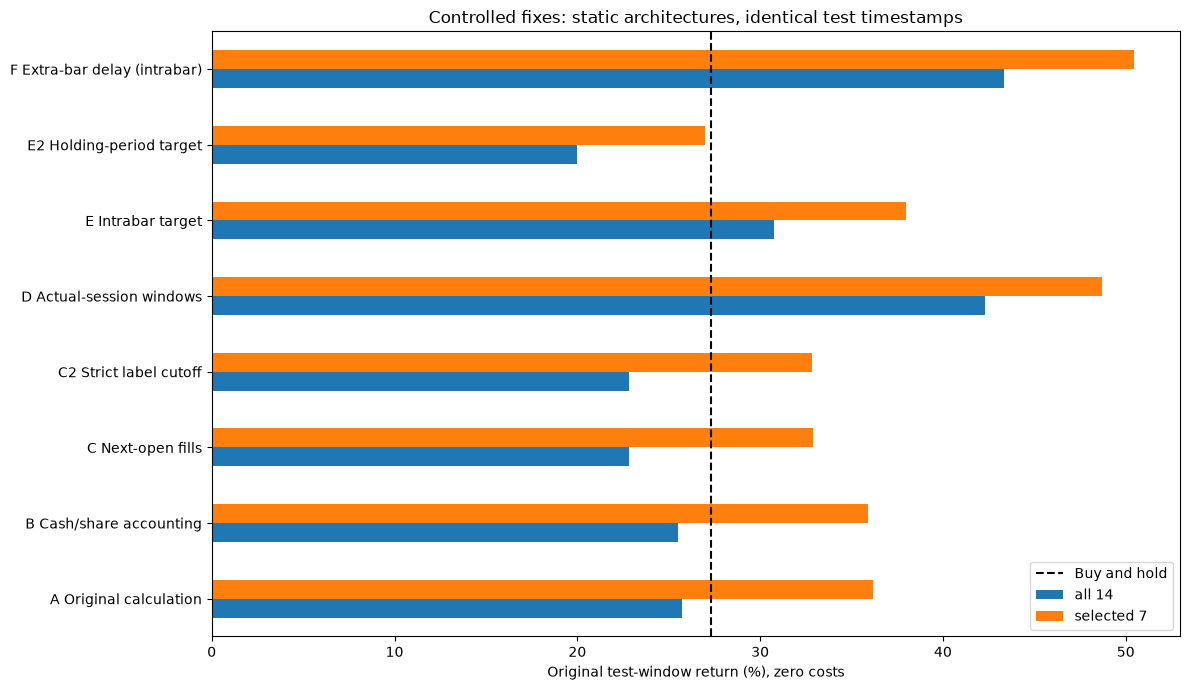

In [21]:
import matplotlib.pyplot as plt

AUDIT_ROOT = Path.cwd()
AUDIT_DATA = AUDIT_ROOT / "data"
AUDIT_OUTPUT = AUDIT_ROOT / "artifacts" / "spy_hourly_audit"
AUDIT_CONFIG = AuditConfig(cost_bps=0.0, sensitivity_cost_bps=1.0)
REBUILD_AUDIT = False
audit_report_path = AUDIT_OUTPUT / "audit_report.json"
audit_report = (
    json.loads(audit_report_path.read_text())
    if audit_report_path.exists()
    else None
)
if (
    REBUILD_AUDIT
    or audit_report is None
    or audit_report.get("fingerprint")
    != audit_fingerprint(AUDIT_DATA, AUDIT_CONFIG)
):
    audit_report = run_audit(AUDIT_DATA, AUDIT_OUTPUT, AUDIT_CONFIG)
controlled = pd.read_csv(AUDIT_OUTPUT / "controlled_results.csv")
controlled_paths = pd.read_csv(
    AUDIT_OUTPUT / "controlled_paths.csv", parse_dates=["datetime"]
)
stage_labels = {
    "A original log accounting": "A Original calculation",
    "B cash/share accounting": "B Cash/share accounting",
    "C next-open fills; same forecasts": "C Next-open fills",
    "C2 strict cutoff; legacy windows": "C2 Strict label cutoff",
    "D session windows + strict label cutoff": "D Actual-session windows",
    "E intrabar target + session windows": "E Intrabar target",
    "E2 next-open holding-period target": "E2 Holding-period target",
    "F extra observed-bar signal delay": "F Extra-bar delay (intrabar)",
    "G nested quarterly selection": "G Quarterly intrabar selection",
    "H nested selection; holding-period target": "H Quarterly holding selection",
}
controlled["repair"] = controlled["stage"].map(stage_labels)
control_table = controlled.pivot(
    index=["repair", "model"], columns="cost_bps", values="return"
)
control_table = (100 * control_table).rename(
    columns={0.0: "return_zero_cost_pct", 1.0: "return_1bp_pct"}
)
display(control_table.round(2))
zero_cost = controlled.loc[controlled["cost_bps"].eq(0)]
static_zero_cost = zero_cost.loc[zero_cost["model"].isin(["selected 7", "all 14"])]
static_zero_cost.pivot(index="repair", columns="model", values="return").mul(
    100
).plot.barh(figsize=(12, 7))
plt.axvline(
    100 * zero_cost.loc[zero_cost["model"].eq("buy and hold"), "return"].iloc[0],
    color="black",
    linestyle="--",
    label="Buy and hold",
)
plt.xlabel("Original test-window return (%), zero costs")
plt.ylabel("")
plt.title("Controlled fixes: static architectures, identical test timestamps")
plt.legend()
plt.tight_layout()
plt.show()


### What the fixes change

For the frozen seven-feature model at zero cost, the return goes from 36.18% with the original log accounting to 35.91% with the cash/share ledger and 32.88% with next-open fills. The strict label cutoff gives 32.85%. Real session windows raise it to 48.69%; intrabar labels give 38.00% and holding-period labels 26.99%, against 27.31% for buy-and-hold. The extra-bar delay (intrabar labels) returns 50.45%. None of these was picked as a winner from this table.

So the fixes don't all push returns down. The accounting and timing fixes lower the frozen result, but new windows and targets change the fitted decisions in either direction. The largest number isn't evidence of the best model: every variant is scored on an already-inspected period with features chosen under the old formulas. An earlier quick estimate of about 33.40% at 1 bp used a different constant-dollar rebalancing rule; the self-financing ledger gives 33.46% at the prior close.

At 1 bp, the reproduced original is 33.74%, cash/share accounting 33.46%, next-open fills 30.48% and session windows 45.49%.

## 14. Corrected chronological re-selection

Fixing the mechanics can't undo that the test period was already inspected, so this experiment evaluates a selection procedure instead of a fixed model. Each quarter from 2020 to July 2026 uses only earlier data. The last 126 New York sessions choose among nine preset logistic models (indicators only, lags only or all 14 features, each with C = 0.1, 1 or 10) and buy-and-hold, ranked by validation portfolio return under the same ledger at zero cost. Ties go to buy-and-hold. Scaling and fitting use only labels available before the inner validation window, and the winner is refit only on labels available before the quarter starts.

The original seven features aren't offered here, since they were chosen using later validation results. Two targets are run separately: intrabar open-to-close and the full open-to-next-open holding period, whose overnight labels wait for the next open. All quarterly decisions are backtested as one continuous account, so quarter boundaries don't reset capital or create free liquidations.

This fixes the chronology and narrows the search from 16,383 subsets, but it still doesn't create an untouched test period or show the strategy is tradable live.

,model,cost_bps,return,daily_sharpe,max_drawdown,long_rate
0,intrabar-label selection,0.0,0.420964,0.369326,-0.389816,0.924391
1,holding-label selection,0.0,1.620748,0.846818,-0.330558,0.957991
2,buy and hold,0.0,1.335095,0.754173,-0.350038,1.000000
3,intrabar-label selection,1.0,0.000676,0.099538,-0.480808,0.924391
4,holding-label selection,1.0,0.938789,0.615276,-0.354407,0.957991
5,buy and hold,1.0,1.334628,0.754020,-0.350038,1.000000


,quarter,choice,C,columns,validation_return,last_inner_training_completion,validation_start,last_refit_completion,outer_start,target
42,2023Q4,indicators,0.1,"ma_distance, upper_relative, lower_relative, p...",0.068365,2023-03-30 23:00:00+00:00,2023-03-31 08:00:00+00:00,2023-09-29 23:00:00+00:00,2023-10-02 08:00:00+00:00,return_oo
43,2024Q1,buy and hold,NaN,NaN,0.071184,2023-06-30 23:00:00+00:00,2023-07-03 08:00:00+00:00,2023-12-30 00:00:00+00:00,2024-01-02 09:00:00+00:00,return_oo
44,2024Q2,buy and hold,NaN,NaN,0.226776,2023-09-27 23:00:00+00:00,2023-09-28 08:00:00+00:00,2024-03-28 23:00:00+00:00,2024-04-01 08:00:00+00:00,return_oo
45,2024Q3,buy and hold,NaN,NaN,0.142693,2023-12-28 00:00:00+00:00,2023-12-28 09:00:00+00:00,2024-06-28 23:00:00+00:00,2024-07-01 08:00:00+00:00,return_oo
46,2024Q4,buy and hold,NaN,NaN,0.098603,2024-04-01 23:00:00+00:00,2024-04-02 08:00:00+00:00,2024-09-30 23:00:00+00:00,2024-10-01 08:00:00+00:00,return_oo
47,2025Q1,lags,0.1,"return_lag_1, return_lag_2, return_lag_3, retu...",0.083399,2024-07-02 23:00:00+00:00,2024-07-03 08:00:00+00:00,2025-01-01 00:00:00+00:00,2025-01-02 09:00:00+00:00,return_oo
48,2025Q2,lags,0.1,"return_lag_1, return_lag_2, return_lag_3, retu...",-0.022063,2024-09-26 23:00:00+00:00,2024-09-27 08:00:00+00:00,2025-03-31 23:00:00+00:00,2025-04-01 08:00:00+00:00,return_oo
49,2025Q3,indicators,0.1,"ma_distance, upper_relative, lower_relative, p...",0.078249,2024-12-24 21:00:00+00:00,2024-12-26 09:00:00+00:00,2025-06-30 23:00:00+00:00,2025-07-01 08:00:00+00:00,return_oo
50,2025Q4,indicators,0.1,"ma_distance, upper_relative, lower_relative, p...",0.272321,2025-03-31 23:00:00+00:00,2025-04-01 08:00:00+00:00,2025-09-30 23:00:00+00:00,2025-10-01 08:00:00+00:00,return_oo
51,2026Q1,buy and hold,NaN,NaN,0.098645,2025-07-03 00:00:00+00:00,2025-07-03 08:00:00+00:00,2026-01-01 00:00:00+00:00,2026-01-02 09:00:00+00:00,return_oo


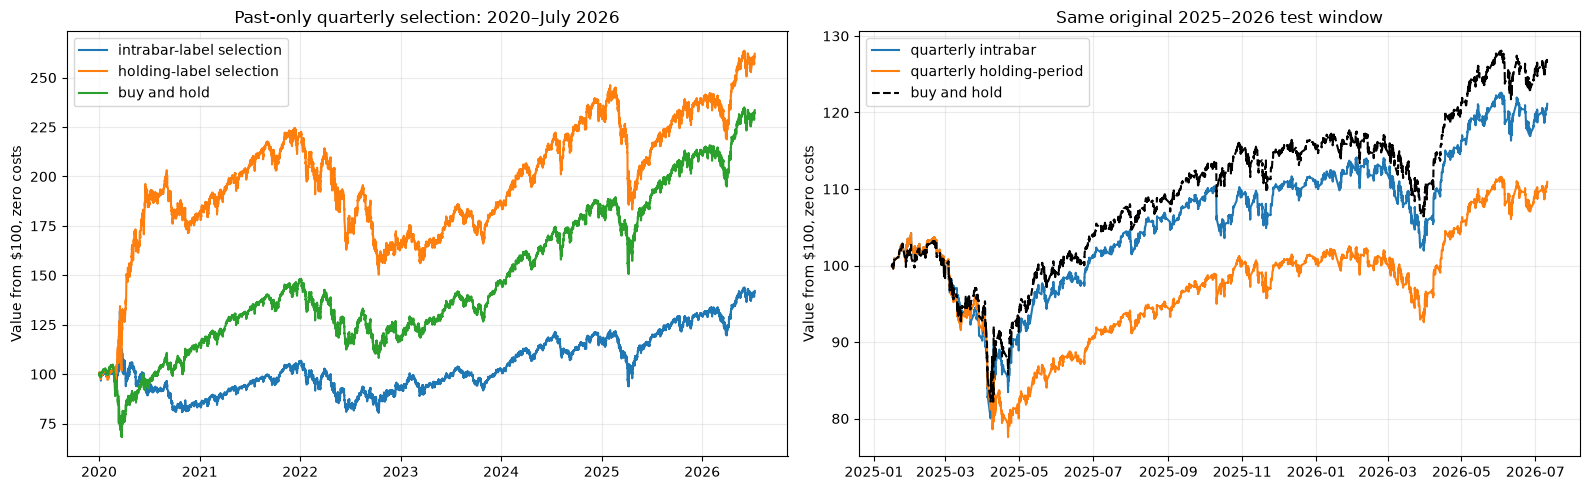

model,buy and hold,holding-label selection,intrabar-label selection
year,,,
2020,15.72,81.93,-15.05
2021,26.91,21.22,24.53
2022,-19.37,-25.06,-11.69
2023,24.01,13.09,9.58
2024,23.46,23.46,13.25
2025,16.37,2.61,11.60
2026,10.69,10.69,9.82


In [22]:
walk_results = pd.read_csv(AUDIT_OUTPUT / "walk_forward_results.csv")
walk_paths = pd.read_csv(
    AUDIT_OUTPUT / "walk_forward_paths.csv", parse_dates=["datetime"]
)
walk_audit = pd.read_csv(
    AUDIT_OUTPUT / "walk_forward_audit.csv",
    parse_dates=[
        "last_inner_training_completion",
        "validation_start",
        "last_refit_completion",
        "outer_start",
    ],
)
assert (
    walk_audit["last_inner_training_completion"]
    .lt(walk_audit["validation_start"])
    .all()
)
assert walk_audit["last_refit_completion"].lt(walk_audit["outer_start"]).all()
assert (
    audit_fingerprint(AUDIT_DATA, AUDIT_CONFIG)
    == audit_report["fingerprint"]
)
display(
    walk_results[
        ["model", "cost_bps", "return", "daily_sharpe", "max_drawdown", "long_rate"]
    ]
)
display(walk_audit.tail(12))
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for model_name, group in walk_paths.loc[walk_paths["cost_bps"].eq(0)].groupby(
    "model", sort=False
):
    axes[0].plot(group["datetime"], 100 * group["equity"], label=model_name)
axes[0].set(
    title="Past-only quarterly selection: 2020–July 2026",
    ylabel="Value from $100, zero costs",
)
axes[0].legend()
for model_name, stage in [
    ("quarterly intrabar", "G nested quarterly selection"),
    ("quarterly holding-period", "H nested selection; holding-period target"),
]:
    group = controlled_paths.loc[
        controlled_paths["stage"].eq(stage)
        & controlled_paths["model"].eq("past-only selection")
        & controlled_paths["cost_bps"].eq(0)
    ]
    axes[1].plot(group["datetime"], 100 * group["equity"], label=model_name)
benchmark = controlled_paths.loc[
    controlled_paths["stage"].eq("H nested selection; holding-period target")
    & controlled_paths["model"].eq("buy and hold")
    & controlled_paths["cost_bps"].eq(0)
]
axes[1].plot(
    benchmark["datetime"],
    100 * benchmark["equity"],
    label="buy and hold",
    color="black",
    linestyle="--",
)
axes[1].set(
    title="Same original 2025–2026 test window", ylabel="Value from $100, zero costs"
)
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()
annual_paths = walk_paths.loc[walk_paths["cost_bps"].eq(0)].copy()
annual_paths["year"] = annual_paths["datetime"].dt.tz_convert("America/New_York").dt.year
annual_table = (
    annual_paths.groupby(["year", "model"])["net_return"]
    .apply(lambda values: (1 + values).prod() - 1)
    .unstack("model")
)
display((100 * annual_table).round(2))


### What survives the repairs

On the original 2025–2026 test timestamps at zero cost, past-only quarterly selection returns 21.13% with intrabar labels and 10.93% with holding-period labels, against 27.31% for buy-and-hold. The best static variants from section 13 don't turn into a consistent win once selection is done chronologically.

Over the whole 2020–July 2026 run, holding-period selection returns 162.07% vs 133.51% for buy-and-hold, with daily Sharpe 0.847 vs 0.754 and max drawdown −33.06% vs −35.00%, but it is long 95.80% of bars. The intrabar version returns 42.10%. These are different targets and procedures, not a menu to pick the best curve from.

At 1 bp the holding-period advantage reverses: 93.88% vs 133.46% for buy-and-hold.

Overall, the audit supports fixing the bookkeeping, timing, label clocks and feature windows, but not the stale 43.30% headline or any corrected static variant as a proven edge. Everything is price-only (no dividends, borrow or funding) and assumes trades fill at observed opens, despite thin extended-hours liquidity and the time needed to compute a signal; the extra-bar-delay case shows that sensitivity.

The 14 tests in the next cell check the window arithmetic (including DST, weekends and missing hours), that future prices can't change current features, the fixed-share short ledger, gap attribution, exact entry and exit costs, daily risk grouping and both label-availability cutoffs. The audit reproduces the original cached result, and the input hashes confirm the data files weren't modified.

In [23]:
# Section 13-14 tests (14): feature windows, cash/share ledger and label timing
import sys
import unittest
from unittest.mock import patch


def run_tests(*cases):
    suite = unittest.TestSuite(unittest.defaultTestLoader.loadTestsFromTestCase(case) for case in cases)
    result = unittest.TextTestRunner(stream=sys.stdout, verbosity=1).run(suite)
    assert result.wasSuccessful(), "a test failed"


def bars_fixture(days=30, start="2024-02-01"):
    dates = pd.bdate_range(start, periods=days)
    times = pd.DatetimeIndex(
        [
            day.tz_localize("America/New_York") + pd.Timedelta(hours=hour)
            for day in dates
            for hour in range(4, 20)
        ]
    ).tz_convert("UTC")
    close = 100 + np.arange(len(times)) * 0.01
    return pd.DataFrame(
        {
            "datetime": times,
            "open": close - 0.02,
            "high": close + 1,
            "low": close - 1,
            "close": close,
        }
    )


def ledger_bars(opens, closes, previous):
    return pd.DataFrame(
        {
            "datetime": pd.date_range(
                "2025-01-02 15:00", periods=len(opens), freq="h", tz="UTC"
            ),
            "open": opens,
            "close": closes,
            "previous_close": previous,
        }
    )


class FeatureWindowTests(unittest.TestCase):
    def test_legacy_formulas_match_direct_arithmetic(self):
        bars = bars_fixture()
        frame = make_features(bars, "legacy")
        position = 100
        previous = bars.close.iloc[position - 1]
        expected_ma = bars.close.iloc[position - 80 : position].mean() - previous
        past = bars.close.iloc[position - 8 : position].to_numpy()
        upper = past.mean() + 2 * past.std(ddof=0)
        self.assertAlmostEqual(frame.ma_distance.iloc[position], expected_ma)
        self.assertAlmostEqual(
            frame.upper_relative.iloc[position], (previous - upper) / upper
        )
        self.assertAlmostEqual(frame.pgo.iloc[position], (previous - past.mean()) / 2)

    def test_actual_session_window_across_weekend_and_dst(self):
        bars = bars_fixture(start="2024-03-01")
        local = bars.datetime.dt.tz_convert("America/New_York")
        monday_five = bars.index[
            (local.dt.date == pd.Timestamp("2024-03-11").date()) & local.dt.hour.eq(5)
        ][0]
        # Forecast at Monday 05:00 uses bars from Friday 05:00 through
        # Monday 04:00, exactly 16 observed bars despite the DST weekend.
        expected = bars.close.iloc[monday_five - 16 : monday_five].to_numpy()
        frame = make_features(bars, "sessions")
        upper = expected.mean() + 2 * expected.std(ddof=0)
        self.assertAlmostEqual(
            frame.upper_relative.iloc[monday_five], (expected[-1] - upper) / upper
        )

    def test_ten_sessions_are_not_eighty_bars(self):
        bars = bars_fixture()
        frame = make_features(bars, "sessions")
        position = 20 * 16 + 6
        expected = (
            bars.close.iloc[position - 160 : position].mean()
            - bars.close.iloc[position - 1]
        )
        self.assertAlmostEqual(frame.ma_distance.iloc[position], expected)
        self.assertNotAlmostEqual(
            frame.ma_distance.iloc[position],
            make_features(bars, "legacy").ma_distance.iloc[position],
        )

    def test_window_uses_available_bars_not_a_fixed_sixteen(self):
        bars = bars_fixture()
        bars = bars.drop(index=16 * 18 + 12).reset_index(drop=True)
        indexer, valid = _session_window(bars.datetime, 1)
        counts = np.arange(1, len(bars) + 1) - indexer.starts
        self.assertTrue((counts[valid] == 15).any())

    def test_current_and_future_prices_cannot_change_current_predictors(self):
        bars = bars_fixture()
        changed = bars.copy()
        changed.loc[250:, ["open", "high", "low", "close"]] *= 2
        for mode in ["legacy", "sessions"]:
            left = make_features(bars, mode)
            right = make_features(changed, mode)
            pd.testing.assert_frame_equal(
                left.loc[:250, FEATURES], right.loc[:250, FEATURES]
            )


class LedgerTests(unittest.TestCase):
    def test_fixed_share_short_does_not_earn_reciprocal_price_return(self):
        frame = ledger_bars([100, 90], [90, 81], [100, 90])
        path = cash_share_path(frame, [-1, -1])
        self.assertAlmostEqual(path.equity.iloc[-1], 1.19)
        self.assertAlmostEqual(path.dollar_turnover.iloc[1], 0.81)  # Final exit only.

    def test_gap_belongs_to_existing_position_not_the_new_prediction(self):
        frame = ledger_bars([100, 110], [100, 100], [100, 100])
        path = cash_share_path(frame, [1, -1])
        self.assertAlmostEqual(path.equity.iloc[-1], 1.2)

    def test_starting_flat_does_not_receive_pre_entry_gap(self):
        frame = ledger_bars([110], [100], [100])
        self.assertAlmostEqual(cash_share_path(frame, [1]).equity.iloc[-1], 100 / 110)
        self.assertAlmostEqual(
            cash_share_path(frame, [1], entry="previous_close").equity.iloc[-1], 1
        )

    def test_buy_hold_and_entry_exit_fees_match_closed_form(self):
        frame = ledger_bars([100, 110], [110, 120], [100, 110])
        path = cash_share_path(frame, [1, 1], cost_bps=1)
        self.assertAlmostEqual(path.equity.iloc[-1], 1.2 * (1 - 0.0001) / (1 + 0.0001))
        self.assertAlmostEqual(path.fees.sum(), 0.0001 * path.dollar_turnover.sum())

    def test_zero_cost_full_long_matches_price_ratio(self):
        bars = bars_fixture()
        bars["previous_close"] = bars.close.shift(1)
        path = cash_share_path(bars, np.ones(len(bars)))
        self.assertAlmostEqual(
            path.equity.iloc[-1], bars.close.iloc[-1] / bars.open.iloc[0]
        )

    def test_daily_risk_groups_by_new_york_session(self):
        frame = ledger_bars([100, 101], [101, 102], [100, 101])
        path = cash_share_path(frame, [1, 1])
        stats = _path_summary(path)
        self.assertEqual(stats["sessions"], 1)
        self.assertAlmostEqual(stats["return"], 0.02)


class ChronologyTests(unittest.TestCase):
    def test_overnight_label_waits_until_next_open_is_observed(self):
        frame = pd.DataFrame(
            {
                "completion": pd.to_datetime(
                    ["2024-12-31 22:00Z", "2025-01-02 10:00Z"]
                ),
                "next_open_time": pd.to_datetime(
                    ["2025-01-02 09:00Z", "2025-01-02 10:00Z"]
                ),
                "return_oc": [0.01, -0.01],
                "return_oo": [0.01, -0.01],
            }
        )
        cutoff = pd.Timestamp("2025-01-01", tz="UTC")
        self.assertEqual(_training_rows(frame, cutoff, "return_oc").index.tolist(), [0])
        self.assertTrue(_training_rows(frame, cutoff, "return_oo").empty)

    def test_inner_training_does_not_consume_validation_labels(self):
        frame = make_features(
            bars_fixture(days=160, start="2021-01-04"), "sessions"
        ).dropna(subset=FEATURES)
        observed = []

        def fake_fit(train, columns, target, c):
            observed.append(train.completion.max())
            return object()

        with (
            patch("__main__._fit", side_effect=fake_fit),
            patch(
                "__main__._predict",
                side_effect=lambda model, test, columns: np.ones(len(test)),
            ),
        ):
            chosen, last, boundary = _choose_on_past(
                frame, AuditConfig(inner_sessions=10)
            )
        self.assertLess(last, boundary)
        self.assertTrue(all(time < boundary for time in observed))
        self.assertEqual(chosen["name"], "buy and hold")  # Ties prefer the benchmark.

    def test_outer_refits_use_only_earlier_completed_labels(self):
        frame = make_features(bars_fixture(days=320, start="2020-01-02"), "sessions")
        chosen = {"name": "buy and hold", "columns": [], "c": None, "score": 0}

        def past_only(history, config):
            return chosen, history.completion.min(), history.datetime.max()

        with patch("__main__._choose_on_past", side_effect=past_only):
            _, audit = _walk_forward(frame, AuditConfig(outer_start="2021-01-01"))
        self.assertTrue(audit.last_refit_completion.lt(audit.outer_start).all())


run_tests(FeatureWindowTests, LedgerTests, ChronologyTests)


.

.

.

.

.

.

... (6 outputs left out)

2021Q1 [return_oc]: chose buy and hold C=None using past validation only


.

.

----------------------------------------------------------------------
Ran 14 tests in 0.868s

OK


## 15. Prespecified model improvements using the same cached data

These arms use the open-to-next-open direction target, quarterly expanding refits and the same outer timestamps, with zero cost as the main case. Arm C and the rules below were fixed before looking at the new results. The helper functions are in the four code cells below.

| Arm | Change |
| --- | --- |
| A | Reproduce the current one-window return selector |
| B | Replace dollar SMA distance with `(SMA10 - previous_close) / previous_close` |
| C (primary) | B plus stable probability/portfolio selection across earlier windows |
| D | C plus New York hour sin/cos and time since the previous observed bar |
| E | C plus lagged relative range, closing location, prior opening gap, and volume and dollar-volume surprises |
| F | C plus both D's and E's features |
| G | C using one extra completed bar of price/volume delay; the clock stays current |

A and B keep the earlier 126-session return selector. C–G compare the same three feature pools and three C values on three earlier, non-overlapping 63-session validation windows, each fit on the expanding history before it. A candidate qualifies if it beats its training-only class-rate forecast on average daily log loss, does so in at least two windows, and beats buy-and-hold's daily log return in at least two windows. Among qualifying models within one standard error of the best log-loss gain, we pick fewer features first and then stronger regularization. If nothing qualifies, the binary trading rules hold buy-and-hold.

Indicator and activity features are lagged; the clock is known at prediction time. Volume surprises are log1p volume minus its one-session average. PGO smoothing is unchanged. Validation labels must be known before their fold ends, and fitting labels before validation or refit begins.

For A and C we also compare long/short and long/cash at 0.5 with a confidence policy that can hold cash. Its half-width (0, 0.025 or 0.05) is chosen on earlier validation by average daily log return, and when no model qualifies it holds cash. So part of any difference can come from market exposure versus cash rather than better forecasts.

Probability scores (log loss, Brier, calibration) are compared against a constant up-rate fitted on each quarter's training data; no extra calibration step is fitted. [Scikit-learn's calibration guide](https://scikit-learn.org/stable/modules/calibration.html) explains why log loss and Brier measure more than calibration alone.

In [24]:
# Section 15-17 helpers: settings, research arms and features (built on the audit helpers)
from sklearn.metrics import roc_auc_score


TARGET = "return_oo"


NORMALIZED = ["ma_distance_pct", *FEATURES[1:]]


ACTIVITY = [
    "relative_range",
    "close_location",
    "previous_gap",
    "volume_surprise",
    "dollar_volume_surprise",
]


CLOCK = ["hour_sin", "hour_cos", "elapsed_hours_log"]


@dataclass(frozen=True)
class ResearchConfig:
    outer_start: str = "2020-01-01"
    diagnostic_start: str = "2025-01-15T20:00:00Z"
    fold_sessions: int = 63
    folds: int = 3
    regularization: tuple[float, ...] = (0.1, 1.0, 10.0)
    confidence_bands: tuple[float, ...] = (0.0, 0.025, 0.05)
    bootstrap_draws: int = 1000
    bootstrap_block_sessions: int = 20
    seed: int = 42


@dataclass(frozen=True)
class Stage:
    name: str
    normalized: bool = True
    stable: bool = True
    activity: bool = False
    clock: bool = False
    delay: bool = False

    @property
    def pools(self):
        core = NORMALIZED if self.normalized else FEATURES
        extras = (ACTIVITY if self.activity else []) + (CLOCK if self.clock else [])
        return {
            "indicators": core[:6] + extras,
            "lags": core[6:] + extras,
            "all": core + extras,
        }


STAGES = (
    Stage("A current", normalized=False, stable=False),
    Stage("B normalize only", stable=False),
    Stage("C stable normalized"),
    Stage("D clock", clock=True),
    Stage("E activity", activity=True),
    Stage("F combined", activity=True, clock=True),
    Stage("G extra-bar delay", delay=True),
)


PRIMARY = "C stable normalized"


METHOD = (
    "Holding-period target; quarterly expanding refits. A/B reproduce single "
    "126-session return selection. C–G use three preceding nonoverlapping "
    "63-session folds. Eligible candidates improve daily log loss against "
    "training-only class priors on average and in at least two folds, and "
    "beat buy-and-hold daily log returns in at least two folds. Among eligible "
    "candidates within one fold-based standard error of the best probability "
    "gain, prefer fewer columns then stronger regularization. Otherwise use "
    "buy-and-hold; confidence policy instead uses cash when no model qualifies. "
    "C is the prespecified primary procedure; D–G are sensitivities, not "
    "test-selected replacements. Primary costs are zero; 1bp is a sensitivity."
)


def study_fingerprint(data_dir="data", config=ResearchConfig()):
    return {
        "audit": audit_fingerprint(data_dir, AuditConfig()),
        "implementation_sha256": code_hash(
            research_features, probability_losses, probability_summary, policy_positions, _daily, _folds,
            _gain_record, _select, _choose_band, _choose, _walk, _daily_path, paired_risk, run_study,
        ),
        "configuration": json.loads(json.dumps(asdict(config))),
    }


def research_features(bars, *, delay=False):
    out = make_features(bars, "sessions")
    out["ma_distance_pct"] = out["ma_distance"] / out["previous_close"]
    spread = bars.high - bars.low
    out["relative_range"] = (spread / bars.close).shift(1)
    out["close_location"] = (
        ((2 * bars.close - bars.high - bars.low) / spread.replace(0, np.nan))
        .where(spread.ne(0), 0.0)
        .shift(1)
    )
    out["previous_gap"] = np.log(bars.open / bars.close.shift(1)).shift(1)
    window, valid = _session_window(out.datetime, 1)
    for source, target in [
        ("volume", "volume_surprise"),
        ("dollar_volume", "dollar_volume_surprise"),
    ]:
        values = bars[source]
        if not np.isfinite(values).all() or values.lt(0).any():
            raise ValueError(f"{source} must be nonnegative and finite")
        logged = np.log1p(values)
        center = logged.rolling(window, min_periods=1).mean().where(valid)
        out[target] = (logged - center).shift(1)
    lagged = list(dict.fromkeys(FEATURES + NORMALIZED + ACTIVITY))
    if delay:
        # Only an extra completed bar of information; current clock is known.
        out[lagged] = out[lagged].shift(1)
    local = out.datetime.dt.tz_convert("America/New_York")
    angle = 2 * np.pi * (local.dt.hour + local.dt.minute / 60) / 24
    out["hour_sin"], out["hour_cos"] = np.sin(angle), np.cos(angle)
    elapsed = out.datetime.diff().dt.total_seconds() / 3600
    out["elapsed_hours_log"] = np.log1p(elapsed)
    out[lagged + CLOCK] = out[lagged + CLOCK].replace([np.inf, -np.inf], np.nan)
    return out


In [25]:
# Section 15-17 helpers: probability scores, trading policies and validation folds
def probability_losses(y, probability):
    y, p = np.asarray(y, float), np.asarray(probability, float)
    if (
        y.shape != p.shape
        or not np.isin(y, [0, 1]).all()
        or not np.isfinite(p).all()
        or ((p < 0) | (p > 1)).any()
    ):
        raise ValueError("Require aligned binary labels and probabilities in [0,1]")
    p = np.clip(p, 1e-12, 1 - 1e-12)
    return -(y * np.log(p) + (1 - y) * np.log1p(-p)), (p - y) ** 2


def probability_summary(frame):
    labeled = frame.loc[frame[TARGET].notna()]
    y = labeled[TARGET].gt(0).astype(int).to_numpy()
    p, prior = labeled.probability.to_numpy(), labeled.prior.to_numpy()
    loss, brier = probability_losses(y, p)
    prior_loss, prior_brier = probability_losses(y, prior)
    return {
        "labeled_bars": len(y),
        "log_loss": loss.mean(),
        "prior_log_loss": prior_loss.mean(),
        "log_loss_gain": (prior_loss - loss).mean(),
        "brier": brier.mean(),
        "prior_brier": prior_brier.mean(),
        "brier_gain": (prior_brier - brier).mean(),
        "accuracy": ((p > 0.5) == y).mean(),
        "auc": roc_auc_score(y, p) if len(np.unique(y)) == 2 else np.nan,
    }


def policy_positions(probability, policy, band=0.0):
    p = np.asarray(probability, float)
    if not np.isfinite(p).all() or ((p < 0) | (p > 1)).any():
        raise ValueError("Invalid probabilities")
    if not 0 <= band < 0.5:
        raise ValueError("Invalid confidence band")
    if policy == "long_short":
        return np.where(p > 0.5, 1.0, -1.0)
    if policy == "long_cash":
        return (p > 0.5).astype(float)
    if policy == "confidence":
        return np.where(p > 0.5 + band, 1.0, np.where(p <= 0.5 - band, -1.0, 0.0))
    raise ValueError(f"Unknown policy: {policy}")


def _daily(values, times, *, aggregate="mean"):
    dates = pd.to_datetime(times, utc=True).dt.tz_convert("America/New_York").dt.date
    return pd.Series(np.asarray(values), index=dates).groupby(level=0).agg(aggregate)


def _folds(history, cutoff, stage, config):
    sessions = sorted(history.session.unique())
    count = config.folds if stage.stable else 1
    width = config.fold_sessions if stage.stable else 126
    if len(sessions) < count * width + 126:
        raise ValueError("Insufficient history for expanding inner folds")
    starts = [
        history.loc[history.session.eq(sessions[-offset * width]), "datetime"].min()
        for offset in range(count, 0, -1)
    ]
    for i, start in enumerate(starts):
        stop = starts[i + 1] if i + 1 < count else cutoff
        train = _training_rows(history, start, TARGET)
        validation = history.loc[history.datetime.ge(start) & history.datetime.lt(stop)]
        yield i, start, stop, train, validation


def _gain_record(prediction, stop):
    known = _training_rows(prediction, stop, TARGET)
    y = known[TARGET].gt(0).astype(int)
    loss, brier = probability_losses(y, known.probability)
    prior_loss, prior_brier = probability_losses(y, known.prior)
    gain = _daily(prior_loss - loss, known.datetime).mean()
    brier_gain = _daily(prior_brier - brier, known.datetime).mean()
    path = cash_share_path(prediction, policy_positions(prediction.probability, "long_short"))
    hold = cash_share_path(prediction, np.ones(len(prediction)))
    excess = _daily(
        np.log1p(path.net_return) - np.log1p(hold.net_return),
        prediction.datetime,
        aggregate="sum",
    ).mean()
    return gain, brier_gain, excess, path.equity.iloc[-1] - 1


In [26]:
# Section 15-17 helpers: candidate selection and the quarterly walk
def _select(records, stage):
    scores = []
    for (pool, c), group in records.groupby(["pool", "C"], sort=False):
        gains = group.log_loss_gain.to_numpy()
        scores.append(
            {
                "pool": pool,
                "C": c,
                "columns": stage.pools[pool],
                "gain": gains.mean(),
                "se": gains.std(ddof=1) / np.sqrt(len(gains)) if len(gains) > 1 else 0,
                "eligible": gains.mean() > 0
                and (gains > 0).sum() >= 2
                and group.excess_daily_log_return.gt(0).sum() >= 2,
                "return": group.portfolio_return.mean(),
            }
        )
    if stage.stable:
        eligible = [s for s in scores if s["eligible"]]
        if not eligible:
            return None
        best = max(eligible, key=lambda s: s["gain"])
        near = [s for s in eligible if s["gain"] >= best["gain"] - best["se"]]
        return min(near, key=lambda s: (len(s["columns"]), s["C"], -s["gain"]))
    best = sorted(scores, key=lambda s: (-s["return"], len(s["columns"]), s["C"]))[0]
    if best["return"] <= records.hold_return.iloc[0] + 1e-12:
        return None
    return best


def _choose_band(validation, config):
    scores = []
    for band in config.confidence_bands:
        folds = []
        for _, fold in validation.groupby("fold"):
            path = cash_share_path(
                fold, policy_positions(fold.probability, "confidence", band)
            )
            folds.append(
                _daily(np.log1p(path.net_return), fold.datetime, aggregate="sum").mean()
            )
        scores.append((np.mean(folds), band))
    # Fixed tie break: smaller band; outer returns never enter this decision.
    return max(scores, key=lambda item: (item[0], -item[1]))[1]


def _choose(history, cutoff, stage, config):
    records, predictions = [], {}
    for fold, start, stop, train, validation in _folds(history, cutoff, stage, config):
        prior = train[TARGET].gt(0).mean()
        hold_return = validation.close.iloc[-1] / validation.open.iloc[0] - 1
        for pool, columns in stage.pools.items():
            for c in config.regularization:
                model = _fit(train, columns, TARGET, c)
                prediction = validation.copy()
                prediction["probability"] = model.predict_proba(validation[columns])[
                    :, 1
                ]
                prediction["prior"], prediction["fold"] = prior, fold
                gain, brier, excess, ret = _gain_record(prediction, stop)
                records.append(
                    {
                        "fold": fold,
                        "pool": pool,
                        "C": c,
                        "log_loss_gain": gain,
                        "brier_gain": brier,
                        "excess_daily_log_return": excess,
                        "portfolio_return": ret,
                        "hold_return": hold_return,
                        "train_rows": len(train),
                        "last_training_label": _label_deadline(train, TARGET).max(),
                        "validation_start": start,
                        "validation_end": stop,
                        "last_scored_label": _label_deadline(
                            _training_rows(prediction, stop, TARGET), TARGET
                        ).max(),
                    }
                )
                predictions.setdefault((pool, c), []).append(prediction)
    records = pd.DataFrame(records)
    chosen = _select(records, stage)
    band = (
        _choose_band(pd.concat(predictions[(chosen["pool"], chosen["C"])]), config)
        if chosen is not None
        else None
    )
    return chosen, band, records


def _walk(frame, stage, config):
    columns = list(dict.fromkeys(sum(stage.pools.values(), [])))
    complete = frame.dropna(subset=columns)
    first = pd.Timestamp(config.outer_start, tz="America/New_York")
    expected = frame.loc[frame.datetime.ge(first), "datetime"].reset_index(drop=True)
    actual = complete.loc[complete.datetime.ge(first), "datetime"].reset_index(
        drop=True
    )
    if not expected.equals(actual):
        raise ValueError("A feature arm changed the outer evaluation timestamps")
    last = frame.datetime.max().tz_convert("America/New_York").tz_localize(None)
    parts, folds, decisions, coefficients = [], [], [], []
    for quarter in pd.period_range(first.tz_localize(None), last, freq="Q"):
        cutoff = quarter.start_time.tz_localize("America/New_York").tz_convert("UTC")
        end = (quarter + 1).start_time.tz_localize("America/New_York").tz_convert("UTC")
        history = complete.loc[complete.completion.lt(cutoff)]
        test = complete.loc[
            complete.datetime.ge(cutoff) & complete.datetime.lt(end)
        ].copy()
        if test.empty:
            continue
        chosen, band, record = _choose(history, cutoff, stage, config)
        record["quarter"], record["stage"] = str(quarter), stage.name
        folds.append(record)
        train = _training_rows(history, cutoff, TARGET)
        prior = train[TARGET].gt(0).mean()
        if chosen is None:
            test["probability"] = prior
            test["long_short"], test["long_cash"], test["confidence"] = 1.0, 1.0, 0.0
        else:
            model = _fit(train, chosen["columns"], TARGET, chosen["C"])
            test["probability"] = model.predict_proba(test[chosen["columns"]])[:, 1]
            for policy in ("long_short", "long_cash", "confidence"):
                test[policy] = policy_positions(test.probability, policy, band)
            fitted = model.named_steps["logisticregression"]
            coefficients.extend(
                {
                    "stage": stage.name,
                    "quarter": str(quarter),
                    "feature": name,
                    "standardized_coefficient": value,
                }
                for name, value in zip(chosen["columns"], fitted.coef_[0])
            )
        test["prior"], test["quarter"] = prior, str(quarter)
        test["stage"], test["fallback"] = stage.name, chosen is None
        parts.append(test)
        decisions.append(
            {
                "stage": stage.name,
                "quarter": str(quarter),
                "choice": chosen["pool"] if chosen else "buy and hold",
                "C": chosen["C"] if chosen else None,
                "columns": ", ".join(chosen["columns"]) if chosen else "",
                "confidence_band": band,
                "training_prior": prior,
                "last_refit_label": _label_deadline(train, TARGET).max(),
                "refit_cutoff": cutoff,
                "outer_start": test.datetime.min(),
                "train_rows": len(train),
            }
        )
        print(f"{stage.name} {quarter}: {decisions[-1]['choice']}", flush=True)
    return (
        pd.concat(parts, ignore_index=True),
        pd.concat(folds, ignore_index=True),
        pd.DataFrame(decisions),
        pd.DataFrame(coefficients),
    )


In [27]:
# Section 15-17 helpers: risk comparison and the full study
def _daily_path(path):
    dates = (
        pd.to_datetime(path.datetime, utc=True)
        .dt.tz_convert("America/New_York")
        .dt.date
    )
    return (1 + path.set_index(dates).net_return).groupby(level=0).prod() - 1


def paired_risk(strategy, market, config):
    """Ex-post beta matching is descriptive, never an input to historical trades."""
    daily = pd.concat([strategy.rename("strategy"), market.rename("market")], axis=1)
    if daily.isna().any().any():
        raise ValueError("Risk comparisons require identical trading dates")
    y, x = daily.strategy.to_numpy(), daily.market.to_numpy()
    design = np.column_stack([np.ones(len(x)), x])
    alpha, beta = np.linalg.lstsq(design, y, rcond=None)[0]
    rng = np.random.default_rng(config.seed)
    length = min(config.bootstrap_block_sessions, len(x))
    boot = []
    for _ in range(config.bootstrap_draws):
        starts = rng.integers(
            0, len(x) - length + 1, size=int(np.ceil(len(x) / length))
        )
        indices = (starts[:, None] + np.arange(length)).ravel()[: len(x)]
        boot.append((y[indices] - x[indices]).mean())
    low, high = np.quantile(boot, [0.025, 0.975])
    return {
        "beta": beta,
        "alpha_daily_bps": alpha * 10000,
        "excess_daily_bps": (y - x).mean() * 10000,
        "excess_daily_bps_ci_low": low * 10000,
        "excess_daily_bps_ci_high": high * 10000,
        "expost_beta_matched_market_return": np.prod(1 + beta * x) - 1,
    }


def run_study(
    data_dir="data", output_dir="artifacts/spy_hourly_research", config=ResearchConfig()
):
    fingerprint = study_fingerprint(data_dir, config)
    bars = pd.read_parquet(Path(data_dir) / "raw" / "SPY" / RAW_NAME)
    bars = bars.sort_values("datetime").reset_index(drop=True)
    frames = {delay: research_features(bars, delay=delay) for delay in (False, True)}
    predictions, fold_records, decisions, coefficients = [], [], [], []
    for stage in STAGES:
        prediction, folds, decision, coefficient = _walk(
            frames[stage.delay], stage, config
        )
        predictions.append(prediction)
        fold_records.append(folds)
        decisions.append(decision)
        coefficients.append(coefficient)
    predictions = pd.concat(predictions, ignore_index=True)
    fold_records = pd.concat(fold_records, ignore_index=True)
    decisions = pd.concat(decisions, ignore_index=True)
    coefficients = pd.concat(coefficients, ignore_index=True)
    baseline = predictions.loc[predictions.stage.eq(STAGES[0].name)].copy()
    paths, portfolio, scores, calibration, annual = [], [], [], [], []
    samples = [
        ("2020 onward", None),
        ("original test", pd.Timestamp(config.diagnostic_start)),
    ]
    # Identical entry and final liquidation conventions for every strategy in each span.
    for span, start in samples:
        market_frame = (
            baseline if start is None else baseline.loc[baseline.datetime.ge(start)]
        )
        market_path = cash_share_path(market_frame, np.ones(len(market_frame)))
        market_daily = _daily_path(market_path)
        portfolio.append(
            {
                "span": span,
                "stage": "buy and hold",
                "policy": "long_short",
                "cost_bps": 0.0,
                **_path_summary(market_path),
            }
        )
        for stage, prediction in predictions.groupby("stage", sort=False):
            frame = (
                prediction
                if start is None
                else prediction.loc[prediction.datetime.ge(start)]
            )
            scores.append({"span": span, "stage": stage, **probability_summary(frame)})
            if start is None:
                labeled = frame.loc[frame[TARGET].notna()]
                for source in ("probability", "prior"):
                    bins = np.minimum((10 * labeled[source]).astype(int), 9)
                    for bin_id, group in labeled.groupby(bins):
                        calibration.append(
                            {
                                "stage": stage,
                                "source": source,
                                "bin": bin_id,
                                "count": len(group),
                                "mean_probability": group[source].mean(),
                                "observed_frequency": group[TARGET].gt(0).mean(),
                            }
                        )
            policies = (
                ("long_short", "long_cash", "confidence")
                if stage in (STAGES[0].name, PRIMARY)
                else ("long_short",)
            )
            for policy in policies:
                for cost in (0.0, 1.0):
                    path = cash_share_path(frame, frame[policy], cost_bps=cost)
                    risk = (
                        paired_risk(_daily_path(path), market_daily, config)
                        if cost == 0
                        else {}
                    )
                    portfolio.append(
                        {
                            "span": span,
                            "stage": stage,
                            "policy": policy,
                            "cost_bps": cost,
                            **_path_summary(path),
                            "cash_rate": frame[policy].eq(0).mean(),
                            **risk,
                        }
                    )
                    if start is None:
                        for key, value in {
                            "stage": stage,
                            "policy": policy,
                            "cost_bps": cost,
                        }.items():
                            path[key] = value
                        paths.append(path)
                        if cost == 0:
                            daily = _daily_path(path)
                            for year, values in daily.groupby(
                                pd.DatetimeIndex(daily.index).year
                            ):
                                annual.append(
                                    {
                                        "stage": stage,
                                        "policy": policy,
                                        "year": year,
                                        "return": (1 + values).prod() - 1,
                                    }
                                )
    if study_fingerprint(data_dir, config) != fingerprint:
        raise ValueError("Study implementation or inputs changed during execution")
    for column, cutoff in [
        ("last_training_label", "validation_start"),
        ("last_scored_label", "validation_end"),
    ]:
        if not (
            pd.to_datetime(fold_records[column], utc=True)
            < pd.to_datetime(fold_records[cutoff], utc=True)
        ).all():
            raise ValueError("An inner fold used unavailable labels")
    if not (
        pd.to_datetime(decisions.last_refit_label, utc=True)
        < pd.to_datetime(decisions.refit_cutoff, utc=True)
    ).all():
        raise ValueError("An outer refit used unavailable labels")
    out = Path(output_dir)
    out.mkdir(parents=True, exist_ok=True)
    prediction_columns = [
        "datetime",
        "stage",
        "quarter",
        "probability",
        "prior",
        TARGET,
        "next_open_time",
        "fallback",
        "long_short",
        "long_cash",
        "confidence",
    ]
    predictions[prediction_columns].to_csv(out / "probabilities.csv", index=False)
    fold_records.to_csv(out / "validation_folds.csv", index=False)
    decisions.to_csv(out / "decisions.csv", index=False)
    coefficients.to_csv(out / "coefficients.csv", index=False)
    pd.concat(paths, ignore_index=True).to_csv(out / "paths.csv", index=False)
    pd.DataFrame(portfolio).to_csv(out / "portfolio_results.csv", index=False)
    pd.DataFrame(scores).to_csv(out / "probability_scores.csv", index=False)
    pd.DataFrame(calibration).to_csv(out / "calibration.csv", index=False)
    pd.DataFrame(annual).to_csv(out / "annual_returns.csv", index=False)
    report = {
        "fingerprint": fingerprint,
        "method": METHOD,
        "primary": PRIMARY,
        "retrospective": True,
        "stages": [asdict(s) for s in STAGES],
        "outer_bars_per_stage": len(baseline),
        "portfolio": portfolio,
        "probability": scores,
        "fallback_quarters": decisions.loc[decisions.choice.eq("buy and hold")]
        .groupby("stage")
        .size()
        .to_dict(),
    }
    (out / "research_report.json").write_text(json.dumps(report, indent=2) + "\n")
    return report


In [28]:
import matplotlib.pyplot as plt

RESEARCH_CONFIG = ResearchConfig()
RESEARCH_OUTPUT = Path("artifacts/spy_hourly_research")
RESEARCH_REPORT = RESEARCH_OUTPUT / "research_report.json"
REBUILD_RESEARCH = False
research_report = (
    json.loads(RESEARCH_REPORT.read_text())
    if RESEARCH_REPORT.exists()
    else None
)
if (
    REBUILD_RESEARCH
    or research_report is None
    or research_report.get("fingerprint")
    != study_fingerprint("data", RESEARCH_CONFIG)
):
    research_report = run_study(config=RESEARCH_CONFIG)
research_portfolio = pd.read_csv(RESEARCH_OUTPUT / "portfolio_results.csv")
research_scores = pd.read_csv(RESEARCH_OUTPUT / "probability_scores.csv")
research_probabilities = pd.read_csv(
    RESEARCH_OUTPUT / "probabilities.csv", parse_dates=["datetime"]
)
research_paths = pd.read_csv(
    RESEARCH_OUTPUT / "paths.csv", parse_dates=["datetime"]
)
research_zero = research_portfolio.loc[research_portfolio["cost_bps"].eq(0)]
research_main = research_zero.loc[research_zero["policy"].eq("long_short")]
display(
    research_main.pivot(index="stage", columns="span", values="return")
    .mul(100)
    .round(2)
)
display(
    research_scores[
        [
            "span",
            "stage",
            "log_loss",
            "prior_log_loss",
            "log_loss_gain",
            "brier_gain",
            "accuracy",
            "auc",
        ]
    ].round(6)
)


span,2020 onward,original test
stage,,
A current,162.07,10.93
B normalize only,163.67,4.89
C stable normalized,104.79,19.20
D clock,209.93,27.31
E activity,124.17,25.25
F combined,120.29,21.23
G extra-bar delay,85.87,28.98
buy and hold,133.51,27.31


,span,stage,log_loss,prior_log_loss,log_loss_gain,brier_gain,accuracy,auc
0,2020 onward,A current,0.692403,0.691833,-0.000569,-0.000223,0.524342,0.503203
1,2020 onward,B normalize only,0.692432,0.691833,-0.000598,-0.000238,0.524381,0.503218
2,2020 onward,C stable normalized,0.692570,0.691833,-0.000737,-0.000309,0.524844,0.496228
3,2020 onward,D clock,0.692526,0.691833,-0.000692,-0.000287,0.526001,0.491715
4,2020 onward,E activity,0.692581,0.691833,-0.000747,-0.000310,0.525654,0.495257
5,2020 onward,F combined,0.691794,0.691833,0.000039,0.000019,0.526811,0.495464
6,2020 onward,G extra-bar delay,0.692759,0.691833,-0.000926,-0.000388,0.525384,0.490445
7,original test,A current,0.692174,0.692215,0.000041,0.000022,0.519192,0.508686
8,original test,B normalize only,0.692286,0.692215,-0.000072,-0.000034,0.518350,0.506240
9,original test,C stable normalized,0.692095,0.692215,0.000119,0.000059,0.521549,0.505263


## 16. Predictive skill, calibration and economic uncertainty

A positive log-loss or Brier gain means the model beat that quarter's training-only constant forecast. Fallback quarters are included and have zero gain by construction. The final bar's next-open label isn't known, so it's left out of scoring but still marks the account. Calibration uses fixed probability bins, shown with their counts.

The zero-cost portfolio table adds long/cash and confidence rules, the average daily excess return with a paired 20-session moving-block bootstrap (1,000 draws), and a regression on daily SPY returns. The beta-matched benchmark uses an after-the-fact beta, so it describes risk rather than a strategy you could have traded, and alpha is just the regression intercept, not a significance test. The bootstrap intervals take the predictions as given: they don't redo model selection or correct for comparing seven arms.

The extra-bar-delay arm is retrained on older information rather than shifting decisions that were already made. Every arm starts a fresh account at the opening price of the original test panel, as in section 13.

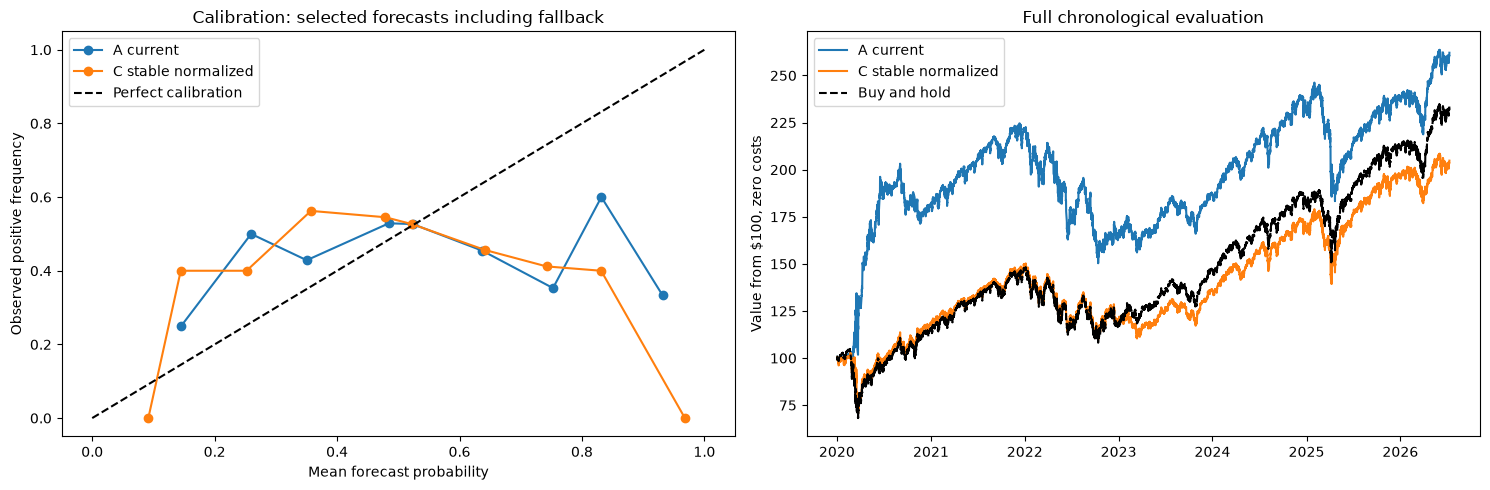

,stage,source,bin,count,mean_probability,observed_frequency
0,A current,probability,1,4,0.145286,0.250000
1,A current,probability,2,10,0.259620,0.500000
2,A current,probability,3,35,0.350383,0.428571
3,A current,probability,4,1040,0.484596,0.528846
4,A current,probability,5,24742,0.523449,0.526797
5,A current,probability,6,66,0.637105,0.454545
6,A current,probability,7,17,0.752699,0.352941
7,A current,probability,8,5,0.831720,0.600000
8,A current,probability,9,3,0.931720,0.333333
9,A current,prior,5,25922,0.522235,0.526387


,span,stage,policy,return,long_rate,cash_rate,beta,alpha_daily_bps,excess_daily_bps,excess_daily_bps_ci_low,excess_daily_bps_ci_high,expost_beta_matched_market_return
1,2020 onward,A current,long_short,1.6207,0.9580,0.0000,0.7134,2.4016,0.6917,-4.3972,7.2941,0.8804
3,2020 onward,A current,long_cash,1.5242,0.9580,0.0420,0.8574,1.2096,0.3585,-2.1931,3.6717,1.1020
5,2020 onward,A current,confidence,1.0017,0.4885,0.4805,0.3924,2.3573,-1.2682,-6.7881,5.3476,0.4385
9,2020 onward,C stable normalized,long_short,1.0479,0.9807,0.0000,0.7531,0.6449,-0.8285,-2.3817,1.1728,0.9400
11,2020 onward,C stable normalized,long_cash,1.2161,0.9807,0.0193,0.8776,0.3068,-0.4235,-1.1981,0.5827,1.1343
13,2020 onward,C stable normalized,confidence,-0.0943,0.1620,0.8237,0.0686,-0.7860,-6.3432,-10.9257,-1.4346,0.0687
24,original test,A current,long_short,0.1093,0.9892,0.0000,0.8385,-2.6752,-3.8294,-11.1820,0.0238,0.2284
26,original test,A current,long_cash,0.1893,0.9892,0.0108,0.9191,-1.3343,-1.9124,-5.5846,0.0118,0.2507
28,original test,A current,confidence,0.1372,0.4136,0.5841,0.3936,0.8610,-3.4739,-12.5194,6.1458,0.1061
32,original test,C stable normalized,long_short,0.1920,0.9852,0.0000,0.9696,-1.5689,-1.7860,-5.1246,0.2366,0.2647


,span,stage,policy,return,max_drawdown
2,2020 onward,A current,long_short,0.9388,-0.3544
4,2020 onward,A current,long_cash,1.1709,-0.3058
6,2020 onward,A current,confidence,0.4749,-0.2768
8,2020 onward,B normalize only,long_short,0.9631,-0.3475
10,2020 onward,C stable normalized,long_short,0.8116,-0.3442
12,2020 onward,C stable normalized,long_cash,1.0841,-0.3189
14,2020 onward,C stable normalized,confidence,-0.2678,-0.3442
16,2020 onward,D clock,long_short,1.8605,-0.2706
18,2020 onward,E activity,long_short,0.9918,-0.3617
20,2020 onward,F combined,long_short,1.0975,-0.3500


In [29]:
research_calibration = pd.read_csv(RESEARCH_OUTPUT / "calibration.csv")
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for stage in ["A current", PRIMARY]:
    selected = research_calibration.loc[
        research_calibration["stage"].eq(stage)
        & research_calibration["source"].eq("probability")
    ]
    axes[0].plot(
        selected["mean_probability"],
        selected["observed_frequency"],
        marker="o",
        label=stage,
    )
    selected_paths = research_paths.loc[
        research_paths["stage"].eq(stage)
        & research_paths["policy"].eq("long_short")
        & research_paths["cost_bps"].eq(0)
    ]
    axes[1].plot(
        selected_paths["datetime"], 100 * selected_paths["equity"], label=stage
    )
axes[0].plot([0, 1], [0, 1], color="black", linestyle="--", label="Perfect calibration")
axes[0].set(
    xlabel="Mean forecast probability",
    ylabel="Observed positive frequency",
    title="Calibration: selected forecasts including fallback",
)
axes[0].legend()
market_probs = research_probabilities.loc[
    research_probabilities["stage"].eq("A current")
]
research_raw = pd.read_parquet(Path("data/raw/SPY") / RAW_NAME).sort_values(
    "datetime"
)
research_market = research_raw.loc[
    research_raw["datetime"].isin(market_probs["datetime"])
]
axes[1].plot(
    research_market["datetime"],
    100 * research_market["close"] / research_market["open"].iloc[0],
    color="black",
    linestyle="--",
    label="Buy and hold",
)
axes[1].set(ylabel="Value from $100, zero costs", title="Full chronological evaluation")
axes[1].legend()
plt.tight_layout()
plt.show()
display(
    research_calibration.loc[
        research_calibration["stage"].isin(["A current", PRIMARY])
    ]
)
display(
    research_zero.loc[
        research_zero["stage"].isin(["A current", PRIMARY]),
        [
            "span",
            "stage",
            "policy",
            "return",
            "long_rate",
            "cash_rate",
            "beta",
            "alpha_daily_bps",
            "excess_daily_bps",
            "excess_daily_bps_ci_low",
            "excess_daily_bps_ci_high",
            "expost_beta_matched_market_return",
        ],
    ].round(4)
)
display(
    research_portfolio.loc[
        research_portfolio["cost_bps"].eq(1),
        ["span", "stage", "policy", "return", "max_drawdown"],
    ].round(4)
)


## 17. Selection and reproducibility checks

Each candidate's fold scores, the chosen feature pool, standardized coefficients, training class rate, confidence threshold and label cutoffs are saved in `artifacts/spy_hourly_research/`. Coefficients are associations inside a fitted model, not causal effects. The original seven features aren't reused here.

The tables below show which pool each arm chose each quarter and how often it fell back to buy-and-hold. The candidate folds show whether an arm failed the probability test, the return test or both. No arm is promoted just because its backtest return is highest.

In [30]:
research_decisions = pd.read_csv(RESEARCH_OUTPUT / "decisions.csv")
research_folds = pd.read_csv(RESEARCH_OUTPUT / "validation_folds.csv")
assert (
    pd.to_datetime(research_folds["last_training_label"], utc=True)
    < pd.to_datetime(research_folds["validation_start"], utc=True)
).all()
assert (
    pd.to_datetime(research_folds["last_scored_label"], utc=True)
    < pd.to_datetime(research_folds["validation_end"], utc=True)
).all()
assert (
    pd.to_datetime(research_decisions["last_refit_label"], utc=True)
    < pd.to_datetime(research_decisions["refit_cutoff"], utc=True)
).all()
assert research_probabilities.groupby("stage").size().nunique() == 1
assert research_report["fingerprint"] == study_fingerprint(
    "data", RESEARCH_CONFIG
)
display(pd.crosstab(research_decisions["stage"], research_decisions["choice"]))
display(
    research_decisions.loc[research_decisions["stage"].eq(PRIMARY)].tail(12)
)
research_annual = pd.read_csv(RESEARCH_OUTPUT / "annual_returns.csv")
display(
    research_annual.loc[research_annual["policy"].eq("long_short")]
    .pivot(index="year", columns="stage", values="return")
    .mul(100)
    .round(2)
)


choice,all,buy and hold,indicators,lags
stage,,,,
A current,3,9,7,8
B normalize only,3,7,9,8
C stable normalized,6,19,1,1
D clock,1,26,0,0
E activity,4,20,1,2
F combined,4,22,1,0
G extra-bar delay,2,20,4,1


,stage,quarter,choice,C,columns,confidence_band,training_prior,last_refit_label,refit_cutoff,outer_start,train_rows
69,C stable normalized,2023Q4,buy and hold,NaN,NaN,NaN,0.522122,2023-09-29 23:00:00+00:00,2023-10-01 04:00:00+00:00,2023-10-02 08:00:00+00:00,28411
70,C stable normalized,2024Q1,buy and hold,NaN,NaN,NaN,0.521723,2023-12-30 00:00:00+00:00,2024-01-01 05:00:00+00:00,2024-01-02 09:00:00+00:00,29416
71,C stable normalized,2024Q2,buy and hold,NaN,NaN,NaN,0.522357,2024-03-28 23:00:00+00:00,2024-04-01 04:00:00+00:00,2024-04-01 08:00:00+00:00,30393
72,C stable normalized,2024Q3,buy and hold,NaN,NaN,NaN,0.522577,2024-06-28 23:00:00+00:00,2024-07-01 04:00:00+00:00,2024-07-01 08:00:00+00:00,31404
73,C stable normalized,2024Q4,buy and hold,NaN,NaN,NaN,0.523345,2024-09-30 23:00:00+00:00,2024-10-01 04:00:00+00:00,2024-10-01 08:00:00+00:00,32426
74,C stable normalized,2025Q1,lags,0.1,"return_lag_1, return_lag_2, return_lag_3, retu...",0.000,0.523681,2025-01-01 00:00:00+00:00,2025-01-01 05:00:00+00:00,2025-01-02 09:00:00+00:00,33444
75,C stable normalized,2025Q2,buy and hold,NaN,NaN,NaN,0.522830,2025-03-31 23:00:00+00:00,2025-04-01 04:00:00+00:00,2025-04-01 08:00:00+00:00,34407
76,C stable normalized,2025Q3,all,0.1,"ma_distance_pct, upper_relative, lower_relativ...",0.050,0.522273,2025-06-30 23:00:00+00:00,2025-07-01 04:00:00+00:00,2025-07-01 08:00:00+00:00,35401
77,C stable normalized,2025Q4,all,0.1,"ma_distance_pct, upper_relative, lower_relativ...",0.025,0.522704,2025-09-30 23:00:00+00:00,2025-10-01 04:00:00+00:00,2025-10-01 08:00:00+00:00,36426
78,C stable normalized,2026Q1,all,0.1,"ma_distance_pct, upper_relative, lower_relativ...",0.025,0.522872,2026-01-01 00:00:00+00:00,2026-01-01 05:00:00+00:00,2026-01-02 09:00:00+00:00,37447


stage,A current,B normalize only,C stable normalized,D clock,E activity,F combined,G extra-bar delay
year,,,,,,,
2020,81.93,81.93,18.76,53.60,15.44,15.72,-6.63
2021,21.22,21.49,25.32,26.91,26.91,26.91,23.58
2022,-25.06,-24.95,-19.37,-19.37,-19.37,-19.37,-19.37
2023,13.09,21.74,13.28,24.01,24.01,24.01,24.01
2024,23.46,21.58,23.46,23.46,20.77,22.31,23.46
2025,2.61,2.61,16.60,16.37,19.26,16.30,17.90
2026,10.69,4.67,4.67,10.69,6.26,5.47,10.69


### Outcome of the improvement study

Over 2020–July 2026 at zero cost, the reproduced current selector (A) returns 162.07%, the stable normalized procedure (C) 104.79% and buy-and-hold 133.51%. On the original 2025–2026 dates, C returns 19.20% vs 27.31% for buy-and-hold. C's full-period log-loss gain over the training-rate baseline is -0.000737 (positive is better), and it falls back to buy-and-hold in 19 of 27 quarters. The paired bootstrap interval for its mean daily excess return is [-2.382, 1.173] bps. Keep the cash-policy comparisons in mind here: returns from staying in the market aren't the same as predictive skill.

The clock arm (D) returns 209.93% over the full period, but it selects a model only in 2020Q1 and falls back to buy-and-hold in the other 26 quarters, so its recent-period return matches the market exactly. Its excess-return interval, [-0.454, 5.429] bps/day, includes zero. That's one concentrated historical result, not evidence that the clock features predict better.

The confidence policy's cash fallback matters a lot: C with the confidence rule returns -9.43% over the full period, versus +121.61% for C long/cash and +133.51% for buy-and-hold. No threshold was changed after seeing this.

Every planned arm is reported, including the worse ones. Better accounting, diagnostics and selection didn't produce a higher backtest, and none of the feature-family or delay arms shows an edge on untouched data. The 16 tests in the next cell (30 in total with section 14's) cover sklearn score parity, analytic feature and risk formulas, price-scale invariance, future-data mutation, label availability, policy boundaries and validation-only threshold selection.

In [31]:
# Section 15-17 tests (16): features, probability scores, selection rules and risk formulas
from sklearn.metrics import brier_score_loss, log_loss


def activity_bars(days=30):
    bars = bars_fixture(days=days)
    bars["volume"] = 100 + np.arange(len(bars)) % 17
    bars["dollar_volume"] = bars.volume * bars.close
    return bars


class ResearchFeatureTests(unittest.TestCase):
    def test_normalized_ma_is_scale_invariant(self):
        bars = activity_bars()
        scaled = bars.copy()
        scaled[["open", "high", "low", "close"]] *= 7
        a, b = research_features(bars), research_features(scaled)
        np.testing.assert_allclose(a[NORMALIZED], b[NORMALIZED], atol=1e-9)
        self.assertAlmostEqual(
            a.ma_distance_pct.iloc[400],
            (bars.close.iloc[240:400].mean() - bars.close.iloc[399])
            / bars.close.iloc[399],
        )

    def test_activity_and_clock_have_analytic_values(self):
        bars = activity_bars()
        frame = research_features(bars)
        i = 400
        self.assertAlmostEqual(frame.relative_range.iloc[i], 2 / bars.close.iloc[i - 1])
        self.assertAlmostEqual(frame.close_location.iloc[i], 0)
        self.assertAlmostEqual(
            frame.previous_gap.iloc[i],
            np.log(bars.open.iloc[i - 1] / bars.close.iloc[i - 2]),
        )
        self.assertAlmostEqual(
            frame.volume_surprise.iloc[i],
            np.log1p(bars.volume.iloc[i - 1])
            - np.log1p(bars.volume.iloc[i - 16 : i]).mean(),
        )
        local = frame.datetime.iloc[i].tz_convert("America/New_York")
        self.assertAlmostEqual(
            frame.hour_sin.iloc[i], np.sin(2 * np.pi * local.hour / 24)
        )

    def test_future_mutation_does_not_change_any_predictor(self):
        bars = activity_bars()
        changed = bars.copy()
        changed.loc[
            250:, ["open", "high", "low", "close", "volume", "dollar_volume"]
        ] *= 3
        for delay in (False, True):
            a, b = (
                research_features(bars, delay=delay),
                research_features(changed, delay=delay),
            )
            pd.testing.assert_frame_equal(
                a.loc[:250, NORMALIZED + ACTIVITY + CLOCK],
                b.loc[:250, NORMALIZED + ACTIVITY + CLOCK],
            )

    def test_delay_uses_one_more_completed_bar_but_current_clock(self):
        bars = activity_bars()
        regular, delayed = research_features(bars), research_features(bars, delay=True)
        np.testing.assert_allclose(
            delayed[NORMALIZED + ACTIVITY].iloc[251],
            regular[NORMALIZED + ACTIVITY].iloc[250],
        )
        pd.testing.assert_frame_equal(regular[CLOCK], delayed[CLOCK])

    def test_zero_volume_and_zero_range_remain_finite_after_warmup(self):
        bars = activity_bars()
        bars["volume"], bars["dollar_volume"] = 0.0, 0.0
        bars.high, bars.low = bars.close, bars.close
        result = research_features(bars)
        self.assertTrue(np.isfinite(result[ACTIVITY].iloc[200:]).all().all())


class ProbabilityTests(unittest.TestCase):
    def test_scores_match_sklearn_and_ignore_unavailable_final_target(self):
        y, p = [0, 1, 0, 1], [0.1, 0.8, 0.4, 0.9]
        loss, brier = probability_losses(y, p)
        self.assertAlmostEqual(loss.mean(), log_loss(y, p))
        self.assertAlmostEqual(brier.mean(), brier_score_loss(y, p))
        frame = pd.DataFrame(
            {TARGET: [-1, 1, -1, 1, np.nan], "probability": [*p, 1], "prior": [0.5] * 5}
        )
        summary = probability_summary(frame)
        self.assertEqual(summary["labeled_bars"], 4)
        self.assertAlmostEqual(summary["prior_log_loss"], np.log(2))

    def test_bad_probabilities_are_rejected(self):
        for p in ([np.nan], [-0.1], [1.1]):
            with self.assertRaises(ValueError):
                probability_losses([1], p)

    def test_position_boundaries_and_cash_band(self):
        p = [0.4, 0.49, 0.5, 0.51, 0.6]
        np.testing.assert_equal(policy_positions(p, "long_short"), [-1, -1, -1, 1, 1])
        np.testing.assert_equal(policy_positions(p, "long_cash"), [0, 0, 0, 1, 1])
        np.testing.assert_equal(policy_positions(p, "confidence", 0.05), [-1, 0, 0, 0, 1])


class SelectionTests(unittest.TestCase):
    def test_one_standard_error_prefers_smaller_pool(self):
        rows = []
        for pool, gains in [("all", [0.023, 0.021, 0.019]), ("lags", [0.0205] * 3)]:
            for gain in gains:
                rows.append(
                    {
                        "pool": pool,
                        "C": 0.1,
                        "log_loss_gain": gain,
                        "excess_daily_log_return": 0.001,
                        "portfolio_return": 0.1,
                    }
                )
        self.assertEqual(_select(pd.DataFrame(rows), STAGES[2])["pool"], "lags")

    def test_single_fold_winner_and_probability_only_winner_are_rejected(self):
        for gains, excess in [
            ([0.1, -0.01, -0.01], [0.01] * 3),
            ([0.01] * 3, [-0.01] * 3),
        ]:
            rows = pd.DataFrame(
                {
                    "pool": ["all"] * 3,
                    "C": [1] * 3,
                    "log_loss_gain": gains,
                    "excess_daily_log_return": excess,
                    "portfolio_return": [0.1] * 3,
                }
            )
            self.assertIsNone(_select(rows, STAGES[2]))

    def test_expanding_folds_are_disjoint_and_labels_purged(self):
        frame = research_features(activity_bars(days=400)).dropna(subset=NORMALIZED)
        cutoff = frame.completion.max() + pd.Timedelta(hours=1)
        config = replace(ResearchConfig(), fold_sessions=20)
        parts = list(_folds(frame, cutoff, STAGES[2], config))
        self.assertEqual(len(parts), 3)
        self.assertTrue(set(parts[0][4].index).isdisjoint(parts[1][4].index))
        self.assertTrue(set(parts[1][4].index).isdisjoint(parts[2][4].index))
        for _, start, _, train, validation in parts:
            self.assertTrue(train.next_open_time.lt(start).all())
            self.assertEqual(validation.session.nunique(), 20)
        self.assertLess(len(parts[0][3]), len(parts[2][3]))

    def test_validation_does_not_score_label_at_next_fold_open(self):
        frame = ledger_bars([100, 101], [101, 102], [99, 100])
        frame["next_open_time"] = [
            frame.datetime.iloc[1],
            frame.datetime.iloc[1] + pd.Timedelta(days=3),
        ]
        frame[TARGET] = [0.01, -0.02]
        frame["probability"], frame["prior"] = [0.9, 0.01], 0.5
        stop = frame.datetime.iloc[1] + pd.Timedelta(hours=1)
        gain, _, _, _ = _gain_record(frame, stop)
        self.assertAlmostEqual(gain, np.log(0.9 / 0.5))

    def test_confidence_band_is_chosen_from_validation_payoffs(self):
        frame = ledger_bars([100, 99], [99, 100], [100, 99])
        frame["probability"], frame["fold"] = [0.51, 0.49], 0
        self.assertEqual(_choose_band(frame, ResearchConfig()), 0.025)

    def test_scaler_never_uses_validation_extremes(self):
        train = pd.DataFrame({"feature": [-2, -1, 1, 2], TARGET: [-1, -1, 1, 1]})
        model = _fit(train, ["feature"], TARGET)
        model.predict_proba(pd.DataFrame({"feature": [1e9]}))
        self.assertAlmostEqual(model.named_steps["standardscaler"].mean_[0], 0)

    def test_fallback_prior_and_policies_use_past_only(self):
        frame = research_features(activity_bars(days=400))
        frame[TARGET] = np.where(frame.datetime.dt.year.eq(2024), -0.01, 0.01)
        config = replace(ResearchConfig(), outer_start="2025-01-01")

        def fallback(history, cutoff, stage, config):
            self.assertTrue(history.completion.lt(cutoff).all())
            return None, None, pd.DataFrame()

        with patch("__main__._choose", side_effect=fallback):
            prediction, _, decision, _ = _walk(frame, STAGES[2], config)
        self.assertTrue(prediction.long_short.eq(1).all())
        self.assertTrue(prediction.confidence.eq(0).all())
        for quarter, group in prediction.groupby("quarter"):
            boundary = decision.loc[decision.quarter.eq(quarter), "refit_cutoff"].iloc[
                0
            ]
            eligible = frame.dropna(subset=NORMALIZED)
            expected = (
                eligible.loc[eligible.next_open_time.lt(boundary), TARGET].gt(0).mean()
            )
            self.assertAlmostEqual(group.prior.iloc[0], expected)


class RiskTests(unittest.TestCase):
    def test_analytic_alpha_beta_and_identical_strategy_bootstrap(self):
        market = pd.Series([-0.02, 0.01, -0.01, 0.03] * 20)
        config = replace(ResearchConfig(), bootstrap_draws=100)
        result = paired_risk(0.001 + 0.4 * market, market, config)
        self.assertAlmostEqual(result["beta"], 0.4)
        self.assertAlmostEqual(result["alpha_daily_bps"], 10)
        identical = paired_risk(market, market, config)
        self.assertEqual(identical["excess_daily_bps_ci_low"], 0)
        self.assertEqual(identical["excess_daily_bps_ci_high"], 0)


run_tests(ResearchFeatureTests, ProbabilityTests, SelectionTests, RiskTests)


.

.

.

.

.

.

... (10 outputs left out)

.

.

.

----------------------------------------------------------------------
Ran 16 tests in 1.987s

OK
